# North Carolina Housing: Main Project Notebook

**Team:** Stephen Dillon, Josiah Bradshaw, Kyle Hampton, Allison Haynes  
**Source snapshot:** four notebooks in the uploaded repository ZIP, dated November 1, 2026.

**Central question:** Where in North Carolina can households with different budgets and preferences find affordable housing with access to the amenities and services they value?

This notebook contains the source preparation, geographic integration, accessibility features, and presentation maps in one ordered workflow. The originals used separate sessions; this version has shared paths, explicit rebuild switches, and a final exported feature table.

## How to run

1. Put this notebook in the project root, beside `data/`.
2. Install the packages in the commented setup line if needed. Select that Python environment as the notebook kernel.
3. For normal team use, keep the rebuild switches **False** and copy the shared `data/processed/` folder into place. This route loads saved preparation results, then recalculates the accessibility features and exports the combined table.
4. To rerun original source preparation, turn on the relevant rebuild switch. Raw files are listed below. Set `REBUILD_AREAS=True` to rebuild the tract/ZCTA intersections and EPA assignment. Boundary files are cached; a first rebuild can download a roughly 504 MB national ZCTA file.
5. Restart the kernel and run all cells in order. Network sources and excluded local data are required only for stages being rebuilt.

### Workflow

- 1. Setup and file checks
- 2. ACS extraction and cleaning
- 3. Zillow and EPA cleaning and population-weighted ZIP export
- 4. OSM, PAD-US, coastal access, rail/bus, and airport preparation
- 5. Tract/ZCTA integration and dominant EPA assignment
- 6. Amenity counts and nearest-access distances
- 7. Validation, exports, maps, and descriptive summaries
- 8. Limitations and remaining analysis

The ZIP contains notebooks but no raw or processed data. No past cell outputs are carried into this notebook as fresh results.

## 1. Shared setup

| Stage | Raw inputs for a rebuild |
|---|---|
| ACS | `data/acs5_2024_tracts_raw.csv` cache, or Census API access |
| Zillow/EPA | `data/zillowzipcode.csv`, `data/SmartLocationDatabase.gdb`; Census 2010 crosswalk is downloaded if absent |
| Amenities | `data/north-carolina.gpkg`, `data/PADUS4_1_StateNC.gdb`; coastal/rail APIs need internet |
| Geographic areas | Four processed housing CSVs and cached/downloadable Census boundaries |

A Census key is read from `CENSUS_API_KEY` in the environment, never embedded in this file. Historical nationwide ACS maps remain available through `DRAW_SOURCE_MAPS`; they run only when rebuilding ACS. Folium is optional.

In [173]:
# Uncomment once if packages are missing, then restart the kernel.
# %pip install pandas numpy requests geopandas pyogrio matplotlib
# Optional interactive map only: %pip install folium

import os
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import geopandas as gpd
import pyogrio
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import BoundaryNorm, ListedColormap
from matplotlib.cm import ScalarMappable
from matplotlib.patches import Patch, Rectangle
from shapely.geometry import box, Point
from IPython.display import display

PROJECT_DIR = Path.cwd()  # Change this if your kernel starts outside the project.
DATA_DIR = PROJECT_DIR / 'data'
PROCESSED_DIR = DATA_DIR / 'processed'
BOUNDARY_DIR = DATA_DIR / 'raw' / 'boundaries'
FIG_DIR = PROJECT_DIR / 'figures'
OUTPUT_DIR = PROCESSED_DIR
for folder in [DATA_DIR, PROCESSED_DIR, BOUNDARY_DIR, FIG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

REBUILD_ACS = False
REBUILD_ZILLOW_EPA = False
REBUILD_AMENITIES = False
REBUILD_AREAS = False
DRAW_SOURCE_MAPS = False
DRAW_PRESENTATION_MAPS = False
DRAW_INTERACTIVE_MAP = False
SEARCH_RADIUS_M = 5000
PROJECT_CRS = 'EPSG:32119'
YEAR = 2024
CENSUS_API_KEY = os.environ.get('CENSUS_API_KEY', '')
OSM_PATH = DATA_DIR / 'north-carolina.gpkg'
PADUS_PATH = DATA_DIR / 'PADUS4_1_StateNC.gdb'
pd.set_option('display.max_columns', 50)
print('Project folder:', PROJECT_DIR)

Project folder: /Users/josiah/2302GroupProj/2302-group-proj


In [174]:
def require_files(paths, purpose):
    missing = [str(path) for path in paths if not path.exists()]
    if missing:
        raise FileNotFoundError(purpose + '\nMissing:\n' + '\n'.join(missing))

def download_cached(url, path):
    path = Path(path)
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(path.suffix + '.part')
        print('Downloading:', path.name)
        with requests.get(url, stream=True, timeout=(30, 180)) as response:
            response.raise_for_status()
            with temporary.open('wb') as file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        file.write(chunk)
        temporary.replace(path)
    return path

def save_gpkg(frame, filename, layer):
    saved = frame.copy()
    for column in saved.columns:
        if isinstance(saved[column].dtype, pd.CategoricalDtype):
            saved[column] = saved[column].astype('string')
    path = PROCESSED_DIR / filename
    path.unlink(missing_ok=True)
    saved.to_file(path, layer=layer, driver='GPKG', engine='pyogrio')

expected = ['nc_acs_2024_tract_clean.csv', 'nc_zillow_zip_clean.csv',
            'nc_epa_2010_tract_clean.csv', 'nc_zillow_epa_zip_clean.csv',
            'osm_amenities_clean.gpkg', 'padus_open_clean.gpkg',
            'nc_coastal_access_clean.gpkg', 'nc_rail_and_bus_access.gpkg',
            'nc_airport_candidates.gpkg', 'nc_housing_epa_integrated.gpkg']
if REBUILD_ZILLOW_EPA:
    require_files([DATA_DIR / 'zillowzipcode.csv', DATA_DIR / 'SmartLocationDatabase.gdb'], 'Zillow/EPA rebuild needs raw inputs.')
else:
    require_files([PROCESSED_DIR / f for f in expected[1:4]], 'Copy the shared processed housing CSVs, or enable their source rebuild.')
if REBUILD_AMENITIES:
    require_files([OSM_PATH, PADUS_PATH], 'Amenity rebuild needs raw geographic files.')
else:
    require_files([PROCESSED_DIR / f for f in expected[4:9]], 'Copy the shared processed amenity files, or enable REBUILD_AMENITIES.')
if not REBUILD_ACS:
    require_files([PROCESSED_DIR / expected[0]], 'Copy the processed ACS CSV, or enable REBUILD_ACS.')
if not REBUILD_AREAS:
    require_files([PROCESSED_DIR / expected[-1]], 'Copy the saved integrated area file, or set REBUILD_AREAS=True.')
display(pd.DataFrame({'processed_file': expected, 'present': [(PROCESSED_DIR / f).exists() for f in expected]}))

,processed_file,present
0,nc_acs_2024_tract_clean.csv,True
1,nc_zillow_zip_clean.csv,True
2,nc_epa_2010_tract_clean.csv,True
3,nc_zillow_epa_zip_clean.csv,True
4,osm_amenities_clean.gpkg,True
5,padus_open_clean.gpkg,True
6,nc_coastal_access_clean.gpkg,True
7,nc_rail_and_bus_access.gpkg,True
8,nc_airport_candidates.gpkg,True
9,nc_housing_epa_integrated.gpkg,True


## 2. ACS extraction and cleaning

Source: `acs_data_cleaning.ipynb`. Set `REBUILD_ACS=True` to execute this section. It preserves the original nationwide extraction and NC-only export. Otherwise the processed NC table is loaded in Section 5.

The five-year estimates cover 2020-2024. Negative missing-value codes become missing, tract GEOIDs stay as text, and reported medians remain medians for the original source tract. `rent_pct_income` is the median gross-rent-to-income percentage, not the percentage of households that are rent burdened.

In [175]:
if REBUILD_ACS:
    # ── Census API key ────────────────────────────────────────────────────────────
    CENSUS_API_KEY = os.environ.get("CENSUS_API_KEY", "")

    # ── Dataset ───────────────────────────────────────────────────────────────────
    YEAR = 2024                    # ACS 5-year release: 2020–2024 estimates
    BASE_URL = f"https://api.census.gov/data/{YEAR}/acs/acs5"   # Detailed Tables endpoint

    # Variables pulled for every tract: {Census variable ID: friendly column name}.
    # Add more as the project grows (the API allows up to 50 per request).
    # Browse variables: https://api.census.gov/data/2024/acs/acs5/variables.html
    VARIABLES = {
        # Mapped measures
        "B19013_001E": "median_hh_income",              # Median household income (2024 dollars)
        "B25064_001E": "median_gross_rent",             # Median gross rent (contract rent + utilities)
        "B25071_001E": "rent_pct_income",               # Median gross rent as % of household income
        "B25077_001E": "median_home_value",             # Median value, owner-occupied units
        "B25105_001E": "median_monthly_housing_cost",   # Median monthly housing costs, all occupied units
        # Supporting fields (counts used to weight averages, plus a margin of error for quality checks)
        "B19013_001M": "median_hh_income_moe",
        "B01003_001E": "total_population",
        "B25003_001E": "occupied_units",                # = households
        "B25003_002E": "owner_units",
        "B25003_003E": "renter_units",
    }

    INCLUDE_PUERTO_RICO = False    # ACS 5-year covers Puerto Rico; set True to add it as a map inset
    NC_FIPS = "37"                 # North Carolina

    # ── Folders ───────────────────────────────────────────────────────────────────
    ACS_CACHE = DATA_DIR / f"acs5_{YEAR}_tracts_raw.csv"

In [176]:
if REBUILD_ACS:
    def _check_key():
        if not CENSUS_API_KEY or CENSUS_API_KEY == "YOUR_API_KEY_HERE":
            raise ValueError(
                "Set CENSUS_API_KEY in the configuration cell (or as an environment variable) "
                "before fetching data. Request a free key at https://api.census.gov/data/key_signup.html"
            )


    def census_get(params, retries=4):
        # Call the ACS API and return the JSON rows (first row is the header).
        params = list(params) + [("key", CENSUS_API_KEY)]
        for attempt in range(retries):
            wait = 2 ** attempt * 2
            try:
                r = requests.get(BASE_URL, params=params, timeout=90)
            except requests.RequestException as e:
                print(f"  network error ({type(e).__name__}); retrying in {wait}s")
                time.sleep(wait)
                continue
            if r.status_code == 200:
                try:
                    return r.json()
                except ValueError:
                    # An invalid or not-yet-activated key returns an HTML page instead of JSON.
                    raise RuntimeError(
                        "The Census API did not return JSON. This usually means the API key is invalid "
                        "or hasn't been activated yet (check your email for the activation link).\n"
                        f"Response begins: {r.text[:200]!r}"
                    )
            if r.status_code in (429, 500, 502, 503, 504):
                print(f"  HTTP {r.status_code}; retrying in {wait}s")
                time.sleep(wait)
                continue
            raise RuntimeError(f"Census API error {r.status_code}: {r.text[:300]}")
        raise RuntimeError("Census API request failed after several retries.")


    def list_states():
        rows = census_get([("get", "NAME"), ("for", "state:*")])
        states = pd.DataFrame(rows[1:], columns=rows[0])
        if not INCLUDE_PUERTO_RICO:
            states = states[states["state"] != "72"]
        return states.sort_values("state").reset_index(drop=True)


    def fetch_state_tracts(state_fips):
        rows = census_get([
            ("get", ",".join(["NAME", *VARIABLES])),
            ("for", "tract:*"),
            ("in", f"state:{state_fips}"),
            ("in", "county:*"),
        ])
        return pd.DataFrame(rows[1:], columns=rows[0])


    def load_or_fetch_acs():
        if ACS_CACHE.exists():
            cached = pd.read_csv(ACS_CACHE, dtype=str)   # dtype=str keeps leading zeros in FIPS codes
            if set(VARIABLES).issubset(cached.columns):
                print(f"Loaded {len(cached):,} tracts from cache ({ACS_CACHE})")
                return cached
            print("Cached file is missing some variables; fetching fresh data.")

        _check_key()
        states = list_states()
        frames = []
        for i, row in states.iterrows():
            print(f"[{i + 1:2d}/{len(states)}] {row['NAME']:<22}", end="")
            df = fetch_state_tracts(row["state"])
            print(f"{len(df):>6,} tracts")
            frames.append(df)
            time.sleep(0.2)   # be polite to the API
        raw = pd.concat(frames, ignore_index=True)
        raw.to_csv(ACS_CACHE, index=False)
        print(f"\nSaved {len(raw):,} tracts to {ACS_CACHE}")
        return raw


    raw = load_or_fetch_acs()
    display(raw.head())

In [177]:
if REBUILD_ACS:
    acs = raw.copy()
    acs["GEOID"] = acs["state"] + acs["county"] + acs["tract"]

    for var_id, name in VARIABLES.items():
        values = pd.to_numeric(acs[var_id], errors="coerce")
        acs[name] = values.mask(values < 0)    # ACS "not available" codes are all negative

    acs = acs[["GEOID", "NAME", "state", "county", "tract", *VARIABLES.values()]]
    acs.to_csv(DATA_DIR / f"acs5_{YEAR}_tracts_clean.csv", index=False)

    print(f"{len(acs):,} tracts")
    display(acs.describe().round(1))

### Optional ACS maps and distributions

The original nationwide and NC choropleths and distributions are retained below. Enable both `REBUILD_ACS` and `DRAW_SOURCE_MAPS` to generate them. A household-weighted average of tract medians is a descriptive summary, not a pooled household median.

In [178]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    def money_short(v):        # $35k, $1.5M
        if v <= 0:
            return "$0"
        return f"${v / 1e6:g}M" if v >= 1e6 else f"${v / 1000:,.0f}k"


    def money_full(v):         # $1,200
        return f"${v:,.0f}"


    def pct(v):                # 30%
        return f"{v:.0f}%"


    MAP_SPECS = {
        "median_hh_income": dict(
            title="Median Household Income",
            label="Median household income (2024 dollars)",
            table="B19013",
            breaks=[0, 35_000, 50_000, 65_000, 80_000, 100_000, 125_000, 150_000, 200_000, 250_000],
            fmt=money_short, top_label="$250k+",
            cmap="magma", cmap_range=(0.08, 0.97),
            weight="occupied_units",
        ),
        "median_gross_rent": dict(
            title="Median Gross Rent",
            label="Median monthly gross rent, including utilities (2024 dollars)",
            table="B25064",
            breaks=[0, 800, 1_000, 1_200, 1_400, 1_600, 1_900, 2_200, 2_700, 3_500],
            fmt=money_full, top_label="$3,500+",
            cmap="viridis", cmap_range=(0.0, 1.0),
            weight="renter_units",
        ),

        # "rent_pct_income": dict(
        #     title="Rent as a Share of Household Income",
        #     label="Median gross rent as % of household income (30%+ = cost-burdened)",
        #     table="B25071",
        #     breaks=[0, 20, 24, 27, 30, 33, 37, 42, 50],
        #     fmt=pct, top_label="50%+",
        #     cmap="RdYlBu_r", cmap_range=(0.0, 1.0),
        #     outline="#555555",      # white borders disappear against the pale middle colors
        #     weight="renter_units",
        # ),
            "rent_pct_income": dict(
            title="Rent as a Share of Household Income",
            label="Median gross rent as % of household income (30%+ = cost-burdened)",
            table="B25071",
            breaks=[0, 20, 25, 30, 35, 40, 50],
            fmt=pct, top_label="50%+",
            # Hand-picked from ColorBrewer RdBu with the pale center shades removed:
            # 3 blues below the 30% threshold, 3 reds above it, so every bin is distinct.
            colors=["#2166ac", "#4393c3", "#92c5de", "#f4a582", "#d6604d", "#b2182b"],
            outline="#555555",
            weight="renter_units",
        ),

        "median_home_value": dict(
            title="Median Home Value",
            label="Median value of owner-occupied homes (2024 dollars)",
            table="B25077",
            breaks=[0, 100_000, 150_000, 200_000, 250_000, 325_000, 400_000, 500_000, 750_000, 1_000_000, 2_000_000],
            fmt=money_short, top_label="$2M+",
            cmap="plasma", cmap_range=(0.0, 0.95),
            weight="owner_units",
        ),

        "median_monthly_housing_cost": dict(
            title="Median Monthly Housing Costs",
            label="Median monthly housing costs, owners and renters (2024 dollars)",
            table="B25105",
            breaks=[0, 600, 800, 1_000, 1_200, 1_500, 1_800, 2_200, 2_800, 4_000],
            fmt=money_full, top_label="$4,000+",
            cmap="YlGnBu", cmap_range=(0.12, 1.0),
            outline="#555555",
            weight="occupied_units",
        ),
    }

    # Draw all of them, or list just the ones you want, e.g. ["median_gross_rent"]
    MAPS_TO_DRAW = list(MAP_SPECS)

In [179]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    def describe_measure(df, col, weight_col):
        v = df[col]
        ok = v.notna() & (df[weight_col] > 0)
        return {
            "Tracts with data": v.notna().sum(),
            "Median of tracts": v.median(),
            "Mean of tracts": v.mean(),
            "Household-weighted mean": np.average(v[ok], weights=df.loc[ok, weight_col]) if ok.any() else np.nan,
            "10th percentile": v.quantile(0.10),
            "90th percentile": v.quantile(0.90),
        }


    rows = []
    nc_acs = acs[acs["state"] == NC_FIPS]
    for col, spec in MAP_SPECS.items():
        for place, df in [("United States", acs), ("North Carolina", nc_acs)]:
            rows.append({"Measure": spec["title"], "Area": place, **describe_measure(df, col, spec["weight"])})

    summary = pd.DataFrame(rows).set_index(["Measure", "Area"])

    # Display: whole numbers, except one decimal for the rent-burden percentages
    shown = summary.apply(lambda c: c.map(lambda v: f"{v:,.0f}"))
    pct_rows = summary.index.get_level_values("Measure") == MAP_SPECS["rent_pct_income"]["title"]
    stat_cols = summary.columns[1:]
    shown.loc[pct_rows, stat_cols] = summary.loc[pct_rows, stat_cols].apply(lambda c: c.map(lambda v: f"{v:.1f}%"))
    display(shown)

In [180]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    GEO_BASE = f"https://www2.census.gov/geo/tiger/GENZ{YEAR}/shp"


    def get_boundaries(layer):
        # layer is "tract", "county", or "state"
        fname = f"cb_{YEAR}_us_{layer}_500k.zip"
        path = DATA_DIR / fname
        if not path.exists():
            print(f"Downloading {fname} ...")
            with requests.get(f"{GEO_BASE}/{fname}", stream=True, timeout=600) as r:
                r.raise_for_status()
                with open(path, "wb") as f:
                    for chunk in r.iter_content(chunk_size=1 << 20):
                        f.write(chunk)
        return gpd.read_file(path)


    keep_states = set(acs["state"])     # the 50 states + DC (+ PR if enabled)

    tracts_geo = get_boundaries("tract")
    tracts_geo = tracts_geo[tracts_geo["STATEFP"].isin(keep_states)]
    counties_geo = get_boundaries("county")
    counties_geo = counties_geo[counties_geo["STATEFP"].isin(keep_states)]
    states_geo = get_boundaries("state")
    states_geo = states_geo[states_geo["STATEFP"].isin(keep_states)]

    # Join ACS values onto tract shapes; drop water-only tracts (no land, no residents)
    gdf = tracts_geo[["GEOID", "STATEFP", "ALAND", "geometry"]].merge(acs, on="GEOID", how="left")
    gdf = gdf[pd.to_numeric(gdf["ALAND"]) > 0]

    unmatched = len(set(acs["GEOID"]) - set(tracts_geo["GEOID"]))
    print(f"{len(gdf):,} tract shapes; ACS tracts without a matching shape: {unmatched}")
    print((gdf[list(MAP_SPECS)].notna().sum()).rename("tracts with data").to_frame())

In [181]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    CONUS_CRS, ALASKA_CRS, HAWAII_CRS, PR_CRS, NC_CRS = "EPSG:5070", "EPSG:3338", "ESRI:102007", "EPSG:32161", "EPSG:32119"
    OUTSIDE_CONUS = ["02", "15", "72"]
    NO_DATA_COLOR = "#cfcfcf"
    SOURCE_NOTE = (f"Source: U.S. Census Bureau, American Community Survey {YEAR - 4}–{YEAR} 5-Year Estimates "
                   f"(Table {{table}}); {YEAR} Cartographic Boundary Files.")

    # National layers
    lower48 = gdf[~gdf["STATEFP"].isin(OUTSIDE_CONUS)].to_crs(CONUS_CRS)
    states48 = states_geo[~states_geo["STATEFP"].isin(OUTSIDE_CONUS)].to_crs(CONUS_CRS)

    inset_specs = [("02", ALASKA_CRS, [0.02, 0.11, 0.24, 0.24]),
                   ("15", HAWAII_CRS, [0.25, 0.13, 0.13, 0.11])]
    if INCLUDE_PUERTO_RICO:
        inset_specs.append(("72", PR_CRS, [0.39, 0.13, 0.08, 0.06]))
    insets = [(gdf[gdf["STATEFP"] == fips].to_crs(crs),
               states_geo[states_geo["STATEFP"] == fips].to_crs(crs), pos)
              for fips, crs, pos in inset_specs]

    # North Carolina layers
    nc = gdf[gdf["STATEFP"] == NC_FIPS].to_crs(NC_CRS)
    nc_counties = counties_geo[counties_geo["STATEFP"] == NC_FIPS].to_crs(NC_CRS)
    nc_outline = states_geo[states_geo["STATEFP"] == NC_FIPS].to_crs(NC_CRS)

    # "side" sets which side of the dot each label sits on, to keep nearby labels from colliding
    cities = pd.DataFrame({
        "name": ["Charlotte", "Raleigh", "Greensboro", "Durham", "Winston-Salem",
                 "Fayetteville", "Wilmington", "Asheville"],
        "lat": [35.2271, 35.7796, 36.0726, 35.9940, 36.0999, 35.0527, 34.2104, 35.5951],
        "lon": [-80.8431, -78.6382, -79.7920, -78.8986, -80.2442, -78.8784, -77.8868, -82.5515],
        "side": ["right", "right", "right", "right", "left", "right", "right", "right"],
    })
    cities = gpd.GeoDataFrame(cities, geometry=gpd.points_from_xy(cities.lon, cities.lat),
                              crs="EPSG:4326").to_crs(NC_CRS)


    # def scale_for(spec):
    #     # Discrete colormap + norm for a measure's bins
    #     lo, hi = spec["cmap_range"]
    #     n_bins = len(spec["breaks"]) - 1
    #     cmap = ListedColormap(plt.get_cmap(spec["cmap"])(np.linspace(lo, hi, n_bins)))
    #     return cmap, BoundaryNorm(spec["breaks"], n_bins)

    def scale_for(spec):
        # Discrete colormap + norm for a measure's bins
        n_bins = len(spec["breaks"]) - 1
        if "colors" in spec:                      # explicit list of colors, one per bin
            assert len(spec["colors"]) == n_bins, f"{spec['title']}: need {n_bins} colors"
            cmap = ListedColormap(spec["colors"])
        else:                                     # sample a named matplotlib colormap
            lo, hi = spec["cmap_range"]
            cmap = ListedColormap(plt.get_cmap(spec["cmap"])(np.linspace(lo, hi, n_bins)))
        return cmap, BoundaryNorm(spec["breaks"], n_bins)

    def plot_tracts(ax, data, col, spec):
        # Fill tracts by bin; values above the last cutoff (incl. top-codes) land in the top bin.
        cmap, norm = scale_for(spec)
        breaks = spec["breaks"]
        has = data[col].notna()
        if has.any():
            vals = data.loc[has, col].clip(lower=breaks[0], upper=breaks[-1] - 1e-6).to_numpy()
            data[has].plot(ax=ax, color=cmap(norm(vals)), linewidth=0)
        if (~has).any():
            data[~has].plot(ax=ax, color=NO_DATA_COLOR, linewidth=0)
        ax.set_axis_off()


    def add_legend(fig, cax, spec):
        cmap, norm = scale_for(spec)
        breaks = spec["breaks"]
        cb = fig.colorbar(ScalarMappable(norm=norm, cmap=cmap), cax=cax, orientation="horizontal",
                          spacing="uniform", ticks=breaks)
        cb.ax.set_xticklabels([spec["fmt"](b) for b in breaks[:-1]] + [spec["top_label"]], fontsize=10)
        cb.outline.set_visible(False)
        cb.ax.tick_params(length=0, pad=4)
        cb.set_label(spec["label"], fontsize=12, labelpad=8)
        cax.legend(handles=[Patch(color=NO_DATA_COLOR, label="No data")], loc="center left",
                   bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=10, handlelength=1.2)

In [182]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    def draw_us_map(col, show=True):
        spec = MAP_SPECS[col]
        fig = plt.figure(figsize=(16, 11))
        ax = fig.add_axes([0.01, 0.12, 0.98, 0.78])
        plot_tracts(ax, lower48, col, spec)
        states48.boundary.plot(ax=ax, color=spec.get("outline", "white"), linewidth=0.5)

        for tracts_inset, outline_inset, pos in insets:
            inset_ax = fig.add_axes(pos)
            plot_tracts(inset_ax, tracts_inset, col, spec)
            outline_inset.boundary.plot(ax=inset_ax, color="#555555", linewidth=0.4)

        fig.text(0.5, 0.955, f"{spec['title']} by Census Tract", ha="center", fontsize=24, weight="bold")
        fig.text(0.5, 0.925, f"United States, ACS {YEAR - 4}–{YEAR} 5-Year Estimates",
                 ha="center", fontsize=14, color="#444444")
        add_legend(fig, fig.add_axes([0.50, 0.08, 0.40, 0.022]), spec)
        fig.text(0.99, 0.015, SOURCE_NOTE.format(table=spec["table"]), ha="right", fontsize=9, color="#666666")

        path = FIG_DIR / f"us_tract_{col}_{YEAR}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
        print(f"Saved {path}")
        if show:
            plt.show()
        plt.close(fig)


    def draw_nc_map(col, show=True):
        spec = MAP_SPECS[col]
        fig, ax = plt.subplots(figsize=(16, 7))
        plot_tracts(ax, nc, col, spec)
        nc_counties.boundary.plot(ax=ax, color=spec.get("outline", "white"), linewidth=0.4, alpha=0.8)
        nc_outline.boundary.plot(ax=ax, color="#333333", linewidth=0.9)

        halo = [pe.withStroke(linewidth=3, foreground="white")]
        for _, c in cities.iterrows():
            left = c["side"] == "left"
            ax.plot(c.geometry.x, c.geometry.y, "o", ms=5, mfc="white", mec="black", mew=1, zorder=5)
            ax.annotate(c["name"], (c.geometry.x, c.geometry.y), xytext=(-6 if left else 6, 5),
                        textcoords="offset points", ha="right" if left else "left",
                        fontsize=11, weight="bold", path_effects=halo, zorder=6)

        ax.set_title(f"{spec['title']} by Census Tract — North Carolina\n"
                     f"ACS {YEAR - 4}–{YEAR} 5-Year Estimates", fontsize=18, weight="bold", pad=14)
        add_legend(fig, ax.inset_axes([0.03, 0.06, 0.46, 0.04]), spec)
        fig.text(0.99, 0.01, SOURCE_NOTE.format(table=spec["table"]), ha="right", fontsize=9, color="#666666")

        path = FIG_DIR / f"nc_tract_{col}_{YEAR}.png"
        fig.savefig(path, dpi=300, bbox_inches="tight", facecolor="white")
        print(f"Saved {path}")
        if show:
            plt.show()
        plt.close(fig)

In [183]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    for col in MAPS_TO_DRAW:
        draw_us_map(col)

In [184]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    for col in MAPS_TO_DRAW:
        draw_nc_map(col)

In [185]:
if REBUILD_ACS and DRAW_SOURCE_MAPS:
    fig, axes = plt.subplots(2, 3, figsize=(16, 8.5))
    for ax, (col, spec) in zip(axes.flat, MAP_SPECS.items()):
        top = spec["breaks"][-1]
        bins = np.linspace(0, top, 31)
        us_vals = acs[col].dropna().clip(upper=top)
        nc_vals = nc_acs[col].dropna().clip(upper=top)
        ax.hist(us_vals, bins=bins, density=True, alpha=0.55, color="#3b528b", label="United States")
        ax.hist(nc_vals, bins=bins, density=True, histtype="step", linewidth=2, color="#e16462",
                label="North Carolina")
        ymax = ax.get_ylim()[1]
        for name, vals, color, y in [("US", us_vals, "#3b528b", 0.93), ("NC", nc_vals, "#e16462", 0.80)]:
            med = vals.median()
            ax.axvline(med, color=color, linestyle="--", linewidth=1.2)
            ax.text(med, ymax * y, f" {name} {spec['fmt'](med)}", color=color, fontsize=10)
        # default args bind this panel's spec (a plain closure would use the last spec in the loop)
        ax.xaxis.set_major_formatter(lambda v, _, s=spec, t=top: s["top_label"] if v >= t else s["fmt"](v))
        ax.set_yticks([])
        ax.spines[["top", "right", "left"]].set_visible(False)
        ax.set_title(spec["title"], fontsize=12, weight="bold", loc="left")

    legend_ax = axes.flat[-1]
    legend_ax.axis("off")
    legend_ax.legend(*axes.flat[0].get_legend_handles_labels(), loc="center", frameon=False, fontsize=13,
                     title="Distribution of tract medians\n(dashed line = median tract)", title_fontsize=12)
    fig.suptitle(f"How North Carolina's Census Tracts Compare to the Nation (ACS {YEAR - 4}–{YEAR})",
                 fontsize=16, weight="bold")
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"distributions_us_vs_nc_{YEAR}.png", dpi=300, bbox_inches="tight", facecolor="white")
    display(plt.show())

In [186]:
if REBUILD_ACS:
    from pathlib import Path

    export_dir = PROCESSED_DIR
    export_dir.mkdir(parents=True, exist_ok=True)

    acs.loc[acs["state"].eq("37")].to_csv(
        export_dir / "nc_acs_2024_tract_clean.csv",
        index=False
    )

    print("Saved NC ACS data.")

## 3. Zillow and EPA preparation

Source: `zillow_epa_data_cleaning.ipynb`. Enable `REBUILD_ZILLOW_EPA` to run this section.

Zillow `home_value` is the latest dated value in the supplied file, while `home_value_12mo` is the mean of up to the final 12 monthly columns. This is a home-value index, not a rental price or observed sale price.

EPA block groups are aggregated to 2010 tracts using population weights. The original population-weighted ZIP version is retained as a secondary export. The final area dataset later uses the **tract-level** EPA table, assigned by geographic overlap.

The original `has_transit` definition uses nonmissing `D4A` as a proxy. Confirm the EPA field definitions and sentinel treatment before interpreting it as confirmed transit service. Aggregated values are population-weighted shares, not binary tract indicators.

In [187]:
if REBUILD_ZILLOW_EPA:
    zillowzipcode = pd.read_csv(DATA_DIR / "zillowzipcode.csv", dtype={"RegionName": str})

In [188]:
if REBUILD_ZILLOW_EPA:
    # Make sure every ZIP is 5 digits (safety check; should already be true with dtype=str)
    zillowzipcode['RegionName'] = zillowzipcode['RegionName'].str.zfill(5)

    # Month columns are the ones whose names start with a year, e.g. '2026-09-30'
    date_cols = sorted([c for c in zillowzipcode.columns if pd.notna(pd.to_datetime(c, format='%Y-%m-%d', errors='coerce'))])
    if not date_cols:
        raise ValueError('Zillow file has no dated monthly columns.')
    zillowzipcode[date_cols] = zillowzipcode[date_cols].apply(pd.to_numeric, errors='coerce')
    latest = date_cols[-1]

    # Build a smaller table: location info + latest value + 12-month average
    zillow = zillowzipcode[['RegionName', 'State', 'City', 'Metro', 'CountyName']].copy()
    zillow['home_value'] = zillowzipcode[latest]
    zillow['home_value_12mo'] = zillowzipcode[date_cols[-12:]].mean(axis=1)

    # Rename RegionName to zip, and drop any ZIP without a current value
    zillow = zillow.rename(columns={'RegionName': 'zip'}).dropna(subset=['home_value'])

    print(zillow.shape)
    display(zillow.head())

In [189]:
if REBUILD_ZILLOW_EPA:
    # Check missing values: count and percent per column
    missing = pd.DataFrame({
        'missing': zillow.isna().sum(),
        'percent': (zillow.isna().mean() * 100).round(1)
    })
    display(missing[missing['missing'] > 0])

In [190]:
if REBUILD_ZILLOW_EPA:
    # Fill missing categories with a label instead of dropping rows.
    # Metro is blank for ~4,709 rural ZIPs that aren't in any metro area. That's real
    # information, not bad data, so we label them 'Non-metro' and keep them.
    # City is blank for 7 ZIPs.
    # fillna only fills empty cells; existing values are untouched.
    # We do NOT fill numeric columns like home_value. Made-up prices would distort the model.
    zillow['Metro'] = zillow['Metro'].fillna('Non-metro')
    zillow['City'] = zillow['City'].fillna('Unknown')

    # Verify: should print 0 for every column
    display(zillow.isna().sum())

In [191]:
if REBUILD_ZILLOW_EPA:
    #IMPORTING SmartLocationDatabase.gdb
    # EPA Smart Location Database: built-environment features per Census block group (~2018 data).
    # read_geometry=False skips the map shapes, which we don't need, so loading is much faster.
    sld_cols = ['GEOID10', 'STATEFP', 'TotPop', 'HH', 'Ac_Land', 'TotEmp',
                'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D4A', 'D5AR', 'NatWalkInd',
                'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker']
    sld = pyogrio.read_dataframe(DATA_DIR / "SmartLocationDatabase.gdb",
                                 columns=sld_cols, read_geometry=False)

    # EPA codes "no value" as -99999 (mostly transit columns), so turn it into real NaN
    sld = sld.replace(-99999, np.nan)

    # Drop territories (Zillow doesn't cover them) and block groups with nobody living there
    sld = sld[~sld['STATEFP'].isin(['60', '66', '69', '72', '78'])]
    sld = sld[sld['TotPop'] > 0]

    # 1 if there's a transit stop within walking distance, 0 if not
    sld['has_transit'] = sld['D4A'].notna().astype(int)

    # First 11 digits of a block group ID = its tract ID
    sld['tract'] = sld['GEOID10'].astype('string').str[:11]

In [192]:
if REBUILD_ZILLOW_EPA:
    # Census crosswalk: which tracts overlap each ZIP, and how many people live in each overlapping piece.
    # (Census calls them ZCTAs, which are their approximation of ZIP codes. 2010 boundaries, matching the SLD.)
    # dtype=str keeps leading zeros on both IDs.
    xw_url = 'https://www2.census.gov/geo/docs/maps-data/data/rel/zcta_tract_rel_10.txt'
    xw = pd.read_csv(download_cached(xw_url, DATA_DIR / 'raw' / 'zcta_tract_rel_10.txt'), usecols=['ZCTA5', 'GEOID', 'POPPT'], dtype={'ZCTA5': str, 'GEOID': str})
    xw = xw.rename(columns={'ZCTA5': 'zip', 'GEOID': 'tract', 'POPPT': 'pop_in_zip'})

    # Drop overlaps where nobody lives (e.g. a ZIP clipping an empty corner of a tract)
    xw = xw[xw['pop_in_zip'] > 0]

In [193]:
if REBUILD_ZILLOW_EPA:
    # Features to average for each ZIP
    rate_cols = ['D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd',
                 'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']

    # Population-weighted average of rate_cols within each group.
    # Missing values are skipped (their weight isn't counted), so they don't drag averages toward 0.
    def weighted_mean(df, group_col, weight_col):
        num = df[rate_cols].mul(df[weight_col], axis=0).groupby(df[group_col]).sum()
        den = df[rate_cols].notna().mul(df[weight_col], axis=0).groupby(df[group_col]).sum()
        return (num / den).reset_index()

    # Step 1: block groups -> tracts, weighted by each block group's population
    sld_by_tract = weighted_mean(sld, 'tract', 'TotPop')

    # Step 2: tracts -> ZIPs, weighted by how many people live in each tract/ZIP overlap
    xw_sld = xw.merge(sld_by_tract, on='tract', how='inner')
    sld_zip = weighted_mean(xw_sld, 'zip', 'pop_in_zip')

    print(sld_by_tract.shape)  # expect (72411, 11)
    print(sld_zip.shape)       # expect (32843, 11)

In [194]:
if REBUILD_ZILLOW_EPA:
    housing = zillow.merge(sld_zip, on='zip', how='inner', validate='one_to_one')

    print(housing.shape)              # expect (26208, 17)
    print(housing.isna().sum().sum()) # expect 0
    display(housing.head())

In [195]:
if REBUILD_ZILLOW_EPA:
    # Which Zillow ZIPs didn't match?
    unmatched = zillow[~zillow['zip'].isin(sld_zip['zip'])]
    print(len(unmatched), 'unmatched')
    display(unmatched.head(10))

In [196]:
if REBUILD_ZILLOW_EPA:
    from pathlib import Path

    export_dir = PROCESSED_DIR
    export_dir.mkdir(parents=True, exist_ok=True)

    # Zillow values by ZIP
    zillow.loc[zillow["State"].eq("NC")].to_csv(
        export_dir / "nc_zillow_zip_clean.csv",
        index=False
    )

    # EPA features by 2010 census tract
    sld_by_tract.loc[
        sld_by_tract["tract"].str.startswith("37")
    ].to_csv(
        export_dir / "nc_epa_2010_tract_clean.csv",
        index=False
    )

    # Existing Zillow + EPA merge by ZIP
    housing.loc[housing["State"].eq("NC")].to_csv(
        export_dir / "nc_zillow_epa_zip_clean.csv",
        index=False
    )

    print("Saved three NC datasets.")

## 4. Amenities and access preparation

Source: `amenities_and_accessibility.ipynb`. Enable `REBUILD_AMENITIES` to run this section.

OSM features are grouped into food/nightlife, shopping/daily needs, sports/fitness, entertainment/culture, and outdoor recreation. Point/polygon duplicates are consolidated only for unambiguous same-name, same-category intersecting pairs. PAD-US records are selected using open-access classifications.

Coastal and rail APIs are retrieved in batches with ID-completeness checks. Airport matches remain candidates. Piedmont Triad was missing in the original snapshot; current matching results are displayed rather than assumed to remain unchanged. These classifications do not verify current schedules or public access.

In [197]:
if REBUILD_AMENITIES:
    # Lists layers without loading all their geographic features
    osm_layers = pd.DataFrame(
        pyogrio.list_layers(OSM_PATH),
        columns=["layer", "geometry_type"]
    )

    padus_layers = pd.DataFrame(
        pyogrio.list_layers(PADUS_PATH),
        columns=["layer", "geometry_type"]
    )

    print("OpenStreetMap layers")
    display(osm_layers)

    print("PAD-US layers")
    display(padus_layers)

In [198]:
if REBUILD_AMENITIES:
    # Businesses and amenities can be mapped as points or area outlines
    osm_poi_points = gpd.read_file(
        OSM_PATH,
        layer="gis_osm_pois_free",
        engine="pyogrio"
    )

    osm_poi_areas = gpd.read_file(
        OSM_PATH,
        layer="gis_osm_pois_a_free",
        engine="pyogrio"
    )

    for label, df in [
        ("POI points", osm_poi_points),
        ("POI areas", osm_poi_areas)
    ]:
        print(f"\n{label}: {len(df):,} records")
        print("CRS:", df.crs)
        print("Columns:", df.columns.tolist())
        display(df.head(3))

In [199]:
if REBUILD_AMENITIES:
    category_counts = pd.concat(
        [
            osm_poi_points["fclass"].value_counts().rename("points"),
            osm_poi_areas["fclass"].value_counts().rename("areas")
        ],
        axis=1
    ).fillna(0).astype(int)

    category_counts["total_records"] = category_counts.sum(axis=1)

    # These are raw record counts, not yet deduplicated venue counts
    display(
        category_counts.sort_values(
            "total_records", ascending=False
        ).rename_axis("category")
    )

In [200]:
if REBUILD_AMENITIES:
    PADUS_LAYER = "PADUS4_1Comb_DOD_Trib_NGP_Fee_Desig_Ease_State_NC"

    # Read a small sample first
    padus_sample = gpd.read_file(
        PADUS_PATH,
        layer=PADUS_LAYER,
        rows=5,
        engine="pyogrio"
    )

    print("PAD-US columns:")
    print(padus_sample.columns.tolist())
    display(padus_sample)

    # Read the lookup table that explains public-access codes
    public_access_lookup = pyogrio.read_dataframe(
        PADUS_PATH,
        layer="Public_Access",
        read_geometry=False
    )

    print("\nPublic-access definitions:")
    display(public_access_lookup)

In [201]:
if REBUILD_AMENITIES:
    padus = gpd.read_file(
        PADUS_PATH,
        layer=PADUS_LAYER,
        engine="pyogrio"
    )

    print(f"PAD-US records: {len(padus):,}")
    print("CRS:", padus.crs)

    display(
        padus.groupby(
            ["Pub_Access", "d_Pub_Access"],
            dropna=False
        ).size().rename("records").reset_index()
    )

In [202]:
if REBUILD_AMENITIES:
    # Keep restricted-access records separately for possible later use
    padus_open = padus[
        padus["Pub_Access"].eq("OA")
    ].copy()

    padus_restricted = padus[
        padus["Pub_Access"].eq("RA")
    ].copy()

    # Remove missing or empty geometries
    padus_open = padus_open[
        padus_open.geometry.notna()
        & ~padus_open.geometry.is_empty
    ].copy()

    # Project to NC State Plane in meters for later distance calculations
    padus_open = padus_open.to_crs("EPSG:32119")

    print(f"Open-access land records: {len(padus_open):,}")

    display(
        padus_open["d_Des_Tp"]
        .value_counts(dropna=False)
        .rename_axis("designation")
        .reset_index(name="records")
    )

    display(
        padus_open[
            ["Unit_Nm", "d_Des_Tp", "d_Pub_Access"]
        ].head(10)
    )

In [203]:
if REBUILD_AMENITIES:
    # Project-defined groups for the recommender
    land_groups = {
        "parks_and_recreation": [
            "Local Park",
            "Local Recreation Area",
            "State Park",
            "State Recreation Area",
            "Recreation Management Area",
            "Access Area"
        ],
        "forests_and_nature": [
            "National Forest",
            "National Park",
            "Inventoried Roadless Area",
            "Local Conservation Area",
            "State Conservation Area",
            "Conservation Area",
            "Private Conservation",
            "National Public Lands",
            "Local Resource Management Area",
            "State Resource Management Area",
            "Watershed Protection Area"
        ],
        "coastal_and_river_lands": [
            "National Lakeshore or Seashore",
            "Wild and Scenic River"
        ],
        "historic_and_cultural": [
            "Local Historic or Cultural Area",
            "State Historic or Cultural Area"
        ]
    }

    designation_to_group = {
        designation: group
        for group, designations in land_groups.items()
        for designation in designations
    }

    padus_open["amenity_group"] = (
        padus_open["d_Des_Tp"]
        .map(designation_to_group)
        .fillna("other_open_land")
    )

    display(
        padus_open.groupby("amenity_group")
        .size()
        .reset_index(name="land_records")
    )

In [204]:
if REBUILD_AMENITIES:
    # Candidate categories to check against your actual OSM data
    candidate_groups = {
        "food_and_nightlife": [
            "restaurant", "fast_food", "cafe", "pub", "bar",
            "biergarten", "nightclub", "food_court"
        ],
        "shopping_and_daily_needs": [
            "supermarket", "convenience", "pharmacy",
            "mall", "department_store", "marketplace"
        ],
        "sports_and_fitness": [
            "sports_centre", "stadium", "pitch", "track",
            "golf_course", "swimming_pool", "fitness_centre"
        ],
        "entertainment_and_culture": [
            "cinema", "theatre", "museum", "arts_centre",
            "theme_park", "zoo", "attraction"
        ],
        "outdoor_recreation": [
            "park", "playground", "picnic_site",
            "viewpoint", "camp_site"
        ]
    }

    # Only display categories that actually exist in your file
    for group, categories in candidate_groups.items():
        available = category_counts.index.intersection(categories)

        print(f"\n{group}")
        print(category_counts.loc[available].to_string())

In [205]:
if REBUILD_AMENITIES:
    # Keep the source layer so we can trace each record
    points = osm_poi_points.copy()
    points["source_layer"] = "gis_osm_pois_free"

    areas = osm_poi_areas.copy()
    areas["source_layer"] = "gis_osm_pois_a_free"

    # Use the same projected CRS for future distance calculations
    points = points.to_crs("EPSG:32119")
    areas = areas.to_crs("EPSG:32119")

    osm_amenities = gpd.GeoDataFrame(
        pd.concat([points, areas], ignore_index=True),
        geometry="geometry",
        crs="EPSG:32119"
    )

    # Assign our project categories
    category_to_group = {
        category: group
        for group, categories in candidate_groups.items()
        for category in categories
    }

    osm_amenities["amenity_group"] = (
        osm_amenities["fclass"].map(category_to_group)
    )

    # Keep selected categories and usable geometry
    osm_amenities = osm_amenities[
        osm_amenities["amenity_group"].notna()
        & osm_amenities.geometry.notna()
        & ~osm_amenities.geometry.is_empty
    ].copy()

    # Clean names without dropping unnamed amenities
    osm_amenities["name"] = (
        osm_amenities["name"]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
    )

    # Traceable record ID, not yet a unique venue ID
    osm_amenities["record_id"] = (
        osm_amenities["source_layer"]
        + ":"
        + osm_amenities["osm_id"].astype("string")
    )

    print(f"Selected amenity records: {len(osm_amenities):,}")

    display(
        osm_amenities.groupby("amenity_group")
        .size()
        .reset_index(name="records")
    )

In [206]:
if REBUILD_AMENITIES:
    # Exact repeated records within the same source layer
    exact_duplicates = osm_amenities.duplicated(
        subset=["source_layer", "osm_id", "fclass", "geometry"]
    )

    print(f"Exact duplicate records: {exact_duplicates.sum():,}")

    osm_amenities = osm_amenities.loc[~exact_duplicates].copy()

    # Repeated names and categories are candidates for review,
    # not confirmed duplicates. Different branches can share a name.
    named = osm_amenities.dropna(subset=["name"]).copy()
    named["name_normalized"] = named["name"].str.casefold()

    potential_duplicates = named[
        named.duplicated(
            subset=["name_normalized", "fclass"],
            keep=False
        )
    ].sort_values(["name_normalized", "fclass"])

    print(f"Records with repeated name/category: {len(potential_duplicates):,}")

    display(
        potential_duplicates[
            ["name", "fclass", "source_layer", "osm_id"]
        ].head(20)
    )

In [207]:
if REBUILD_AMENITIES:
    # Separate named point and polygon records
    poi_points = named[
        named.geometry.geom_type.eq("Point")
    ].copy()

    poi_areas = named[
        named.geometry.geom_type.isin(["Polygon", "MultiPolygon"])
    ].copy()

    # Find points inside or on the boundary of amenity polygons
    matches = gpd.sjoin(
        poi_points[
            ["record_id", "name", "name_normalized", "fclass", "geometry"]
        ],
        poi_areas[
            ["record_id", "name_normalized", "fclass", "geometry"]
        ],
        how="inner",
        predicate="intersects",
        lsuffix="point",
        rsuffix="area"
    )

    # Keep only matching names AND categories
    duplicate_candidates = matches[
        matches["name_normalized_point"].eq(
            matches["name_normalized_area"]
        )
        & matches["fclass_point"].eq(matches["fclass_area"])
    ].copy()

    print(f"Potential point/polygon duplicate pairs: {len(duplicate_candidates):,}")

    display(
        duplicate_candidates[
            ["name", "fclass_point", "record_id_point", "record_id_area"]
        ].head(20)
    )

In [208]:
if REBUILD_AMENITIES:
    # Count how many different features match each point and polygon
    pairs = duplicate_candidates[
        ["record_id_point", "record_id_area"]
    ].drop_duplicates()

    point_matches = pairs.groupby("record_id_point")[
        "record_id_area"
    ].nunique()

    area_matches = pairs.groupby("record_id_area")[
        "record_id_point"
    ].nunique()

    # Only consolidate unambiguous one-to-one matches
    clear_pairs = pairs[
        pairs["record_id_point"].map(point_matches).eq(1)
        & pairs["record_id_area"].map(area_matches).eq(1)
    ].copy()

    # Keep an audit table of the point records excluded
    osm_duplicate_audit = clear_pairs.copy()
    osm_duplicate_audit["reason"] = (
        "Same name and category; point intersects polygon; one-to-one match"
    )

    # Create a separate cleaned table, retaining the polygon representation
    osm_amenities_clean = osm_amenities[
        ~osm_amenities["record_id"].isin(clear_pairs["record_id_point"])
    ].copy()

    print(f"Point records excluded: {len(clear_pairs):,}")
    print(f"Remaining amenity records: {len(osm_amenities_clean):,}")
    print(f"Ambiguous pairs retained: {len(pairs) - len(clear_pairs):,}")

    display(
        osm_amenities_clean.groupby("amenity_group")
        .size()
        .reset_index(name="records")
    )

In [209]:
if REBUILD_AMENITIES:
    OUTPUT_DIR = PROCESSED_DIR
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    osm_amenities_clean.to_file(
        OUTPUT_DIR / "osm_amenities_clean.gpkg",
        layer="amenities",
        driver="GPKG",
        engine="pyogrio"
    )

    osm_duplicate_audit.to_csv(
        OUTPUT_DIR / "osm_duplicate_audit.csv",
        index=False
    )

    print("Saved cleaned OSM amenities and duplicate audit.")

In [210]:
if REBUILD_AMENITIES:
    BEACH_URL = (
        "https://services2.arcgis.com/kCu40SDxsCGcuUWO/"
        "ArcGIS/rest/services/DCM_Beach_and_Waterfront_Access/"
        "FeatureServer/0"
    )

    def arcgis_request(url, params):
        response = requests.post(url, data=params, timeout=120)
        response.raise_for_status()
        data = response.json()

        if "error" in data:
            raise RuntimeError(data["error"])

        return data


    # Get IDs first so we can request every record in manageable batches
    id_response = arcgis_request(
        f"{BEACH_URL}/query",
        {
            "where": "1=1",
            "returnIdsOnly": "true",
            "f": "json"
        }
    )

    object_ids = sorted(id_response.get("objectIds") or [])

    if not object_ids:
        raise ValueError("The beach API returned no record IDs.")

    features = []

    for start in range(0, len(object_ids), 500):
        batch_ids = object_ids[start:start + 500]

        batch = arcgis_request(
            f"{BEACH_URL}/query",
            {
                "objectIds": ",".join(map(str, batch_ids)),
                "outFields": "*",
                "returnGeometry": "true",
                "outSR": 4326,
                "f": "geojson"
            }
        )

        if batch.get("exceededTransferLimit"):
            raise RuntimeError("API response was truncated. Reduce batch size.")

        features.extend(batch["features"])

    beach_access = gpd.GeoDataFrame.from_features(
        features,
        crs="EPSG:4326"
    )

    # Verify IDs as well as the number of records
    id_field = id_response["objectIdFieldName"]
    received_ids = set(beach_access[id_field])

    if (
        received_ids != set(object_ids)
        or len(beach_access) != len(object_ids)
    ):
        raise ValueError("Retrieved records do not match the requested IDs.")

    print(f"Retrieved {len(beach_access):,} coastal-access records.")
    print("Columns:", beach_access.columns.tolist())

    display(beach_access.head(3))

In [211]:
if REBUILD_AMENITIES:
    display(
        beach_access["ACESS_TYPE"]
        .value_counts(dropna=False)
        .rename_axis("access_type")
        .reset_index(name="records")
    )

    print(
        "Missing or empty geometries:",
        (
            beach_access.geometry.isna()
            | beach_access.geometry.is_empty
        ).sum()
    )

In [212]:
if REBUILD_AMENITIES:
    beach_access_clean = beach_access.copy()

    beach_access_clean["access_type_clean"] = (
        beach_access_clean["ACESS_TYPE"]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .fillna("Unknown")
    )

    # Remove unusable locations
    usable_geometry = (
        beach_access_clean.geometry.notna()
        & ~beach_access_clean.geometry.is_empty
    )

    print(f"Records without usable geometry: {(~usable_geometry).sum():,}")

    beach_access_clean = (
        beach_access_clean.loc[usable_geometry]
        .copy()
        .to_crs("EPSG:32119")
    )

    # Separate subsets for later distance calculations
    beach_points = beach_access_clean[
        beach_access_clean["access_type_clean"].eq("Beach")
    ].copy()

    shoreline_points = beach_access_clean[
        beach_access_clean["access_type_clean"].eq("Shoreline")
    ].copy()

    beach_access_clean.to_file(
        OUTPUT_DIR / "nc_coastal_access_clean.gpkg",
        layer="coastal_access",
        driver="GPKG",
        engine="pyogrio"
    )

    print("Saved coastal-access data.")

In [213]:
if REBUILD_AMENITIES:
    RAIL_URL = (
        "https://gis11.services.ncdot.gov/arcgis/rest/services/"
        "NCDOT_RailSystem/MapServer/0"
    )

    # Get all facility IDs
    rail_id_response = arcgis_request(
        f"{RAIL_URL}/query",
        {
            "where": "1=1",
            "returnIdsOnly": "true",
            "f": "json"
        }
    )

    rail_ids = sorted(rail_id_response.get("objectIds") or [])

    if not rail_ids:
        raise ValueError("The rail API returned no record IDs.")

    rail_features = []

    for start in range(0, len(rail_ids), 100):
        batch_ids = rail_ids[start:start + 100]

        batch = arcgis_request(
            f"{RAIL_URL}/query",
            {
                "objectIds": ",".join(map(str, batch_ids)),
                "outFields": "*",
                "returnGeometry": "true",
                "outSR": 4326,
                "f": "geojson"
            }
        )

        if batch.get("exceededTransferLimit"):
            raise RuntimeError("Rail response was truncated.")

        rail_features.extend(batch["features"])

    rail_facilities = gpd.GeoDataFrame.from_features(
        rail_features,
        crs="EPSG:4326"
    )

    # Confirm that every requested record was retrieved exactly once
    rail_id_field = rail_id_response["objectIdFieldName"]

    if (
        set(rail_facilities[rail_id_field]) != set(rail_ids)
        or len(rail_facilities) != len(rail_ids)
    ):
        raise ValueError("Retrieved rail records do not match requested IDs.")

    print(f"Retrieved {len(rail_facilities):,} rail facilities.")

    display(
        rail_facilities["FacType"]
        .value_counts(dropna=False)
        .rename_axis("facility_type")
        .reset_index(name="records")
    )

In [214]:
if REBUILD_AMENITIES:
    # Select station candidates from the downloaded rail facilities
    station_mask = (
        rail_facilities["FacType"]
        .astype("string")
        .str.contains("Station", case=False, na=False)
    )

    rail_station_candidates = rail_facilities.loc[station_mask].copy()

    display(
        rail_station_candidates[
            ["LocationNa", "FacType", "Railroad", "County"]
        ].sort_values(["FacType", "LocationNa"])
    )

In [215]:
if REBUILD_AMENITIES:
    facility_type = (
        rail_station_candidates["FacType"]
        .astype("string")
        .str.strip()
    )

    rail_stations = rail_station_candidates[
        facility_type.eq("Station")
    ].copy()

    amtrak_bus_stops = rail_station_candidates[
        facility_type.eq("Station| Amtrak Bus")
    ].copy()

    rail_stations["access_mode"] = "passenger_rail"
    amtrak_bus_stops["access_mode"] = "amtrak_bus"

    transport_access = gpd.GeoDataFrame(
        pd.concat(
            [rail_stations, amtrak_bus_stops],
            ignore_index=True
        ),
        geometry="geometry",
        crs=rail_facilities.crs
    )

    # Check locations before saving
    usable = (
        transport_access.geometry.notna()
        & ~transport_access.geometry.is_empty
    )

    print(f"Records without usable geometry: {(~usable).sum():,}")

    transport_access = (
        transport_access.loc[usable]
        .copy()
        .to_crs("EPSG:32119")
    )

    transport_access.to_file(
        OUTPUT_DIR / "nc_rail_and_bus_access.gpkg",
        layer="transport_access",
        driver="GPKG",
        engine="pyogrio"
    )

    display(
        transport_access.groupby("access_mode")
        .size()
        .reset_index(name="records")
    )

In [216]:
if REBUILD_AMENITIES:
    osm_transport_points = gpd.read_file(
        OSM_PATH,
        layer="gis_osm_transport_free",
        engine="pyogrio"
    )

    osm_transport_areas = gpd.read_file(
        OSM_PATH,
        layer="gis_osm_transport_a_free",
        engine="pyogrio"
    )

    transport_categories = pd.concat(
        [
            osm_transport_points["fclass"]
            .value_counts().rename("points"),

            osm_transport_areas["fclass"]
            .value_counts().rename("areas")
        ],
        axis=1
    ).fillna(0).astype(int)

    print(transport_categories.to_string())

In [217]:
if REBUILD_AMENITIES:
    airport_parts = []

    for source_layer, df in [
        ("gis_osm_transport_free", osm_transport_points),
        ("gis_osm_transport_a_free", osm_transport_areas)
    ]:
        subset = df[
            df["fclass"].isin(["airport", "airfield"])
        ].copy()

        subset["source_layer"] = source_layer
        airport_parts.append(subset.to_crs("EPSG:32119"))

    airport_inventory = gpd.GeoDataFrame(
        pd.concat(airport_parts, ignore_index=True),
        geometry="geometry",
        crs="EPSG:32119"
    )

    # Compact list of distinct names for review
    airport_names = (
        airport_inventory["name"]
        .astype("string")
        .str.strip()
        .replace("", pd.NA)
        .dropna()
        .drop_duplicates()
        .sort_values()
    )

    print(f"Airport/airfield records: {len(airport_inventory):,}")
    print("\nDistinct airport names:")
    print(airport_names.head(30).to_string(index=False))
    print("Showing at most 30 names; the full airport_inventory remains available.")

In [218]:
if REBUILD_AMENITIES:
    # Name patterns for NC's commercial passenger airport shortlist
    airport_patterns = {
        "Charlotte Douglas": r"charlotte.*douglas",
        "Raleigh-Durham": r"raleigh.*durham",
        "Piedmont Triad": r"piedmont.*triad",
        "Asheville": r"asheville.*regional",
        "Wilmington": r"wilmington.*international",
        "Fayetteville": r"fayetteville.*regional",
        "Albert J. Ellis": r"albert.*ellis",
        "Coastal Carolina": r"coastal.*carolina",
        "Pitt-Greenville": r"pitt.*greenville",
        "Concord-Padgett": r"concord.*(?:padgett|regional)"
    }

    airport_matches = []

    for airport, pattern in airport_patterns.items():
        matches = airport_inventory[
            airport_inventory["name"]
            .astype("string")
            .str.contains(pattern, case=False, regex=True, na=False)
        ].copy()

        matches["airport_group"] = airport
        airport_matches.append(matches)

    commercial_airport_candidates = gpd.GeoDataFrame(
        pd.concat(airport_matches, ignore_index=True),
        geometry="geometry",
        crs=airport_inventory.crs
    )

    # Small summary that won't flood the output
    summary = pd.DataFrame({
        "airport": list(airport_patterns),
        "matching_osm_records": [
            commercial_airport_candidates["airport_group"].eq(name).sum()
            for name in airport_patterns
        ]
    })

    display(summary)

In [219]:
if REBUILD_AMENITIES:
    padus_open.to_file(
        OUTPUT_DIR / "padus_open_clean.gpkg",
        layer="open_access_land",
        driver="GPKG",
        engine="pyogrio"
    )

    print(f"Saved {len(padus_open):,} open-access land records.")

In [220]:
if REBUILD_AMENITIES:
    commercial_airport_candidates.to_file(
        OUTPUT_DIR / "nc_airport_candidates.gpkg",
        layer="airport_candidates",
        driver="GPKG",
        engine="pyogrio"
    )

    print(f"Saved {len(commercial_airport_candidates):,} airport candidate records.")

## 5. Housing geography and integration

Load the prepared housing tables, then either load saved area polygons or rebuild them. Source: `data_intergration.ipynb`.

A tract/ZCTA intersection defines each final housing area. EPA's 2010 boundaries can fragment those polygons, so temporary overlap pieces are used only to select the largest-overlap EPA tract. The final dataset retains the original tract/ZCTA shapes, the EPA overlap share, and a flag below 90% coverage. No housing values are estimated at a finer resolution than their original source measurement.

In [221]:
# Read geographic IDs as text to preserve leading zeros
acs_nc = pd.read_csv(
    PROCESSED_DIR / "nc_acs_2024_tract_clean.csv",
    dtype={
        "GEOID": "string",
        "state": "string",
        "county": "string",
        "tract": "string"
    }
)

epa_nc = pd.read_csv(
    PROCESSED_DIR / "nc_epa_2010_tract_clean.csv",
    dtype={"tract": "string"}
)

zillow_nc = pd.read_csv(
    PROCESSED_DIR / "nc_zillow_zip_clean.csv",
    dtype={"zip": "string"}
)

housing_zip_nc = pd.read_csv(
    PROCESSED_DIR / "nc_zillow_epa_zip_clean.csv",
    dtype={"zip": "string"}
)

# Check row counts and unique geographic IDs
tables = {
    "ACS 2024 tracts": (acs_nc, "GEOID"),
    "EPA 2010 tracts": (epa_nc, "tract"),
    "Zillow ZIPs": (zillow_nc, "zip"),
    "Zillow + EPA ZIPs": (housing_zip_nc, "zip")
}

checks = []

for name, (df, id_col) in tables.items():
    checks.append({
        "dataset": name,
        "rows": len(df),
        "missing_ids": df[id_col].isna().sum(),
        "duplicate_ids": df[id_col].duplicated().sum()
    })

display(pd.DataFrame(checks))

for name, (df, _) in tables.items():
    print(f"\n{name} columns:")
    print(df.columns.tolist())

,dataset,rows,missing_ids,duplicate_ids
0,ACS 2024 tracts,2672,0,0
1,EPA 2010 tracts,2171,0,0
2,Zillow ZIPs,719,0,0
3,Zillow + EPA ZIPs,717,0,0



ACS 2024 tracts columns:
['GEOID', 'NAME', 'state', 'county', 'tract', 'median_hh_income', 'median_gross_rent', 'rent_pct_income', 'median_home_value', 'median_monthly_housing_cost', 'median_hh_income_moe', 'total_population', 'occupied_units', 'owner_units', 'renter_units']

EPA 2010 tracts columns:
['tract', 'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd', 'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']

Zillow ZIPs columns:
['zip', 'State', 'City', 'Metro', 'CountyName', 'home_value', 'home_value_12mo']

Zillow + EPA ZIPs columns:
['zip', 'State', 'City', 'Metro', 'CountyName', 'home_value', 'home_value_12mo', 'D1A', 'D1C', 'D2B_E8MIXA', 'D3B', 'D5AR', 'NatWalkInd', 'Pct_AO0', 'R_PCTLOWWAGE', 'VMT_per_worker', 'has_transit']


In [222]:
for name, (frame, identifier) in tables.items():
    expected_length = 5 if identifier == 'zip' else 11
    valid = frame[identifier].astype('string').str.fullmatch(rf'\d{{{expected_length}}}', na=False)
    if not valid.all() or frame[identifier].duplicated().any():
        raise ValueError(f'{name}: IDs must be unique {expected_length}-digit strings.')
if not REBUILD_AREAS:
    housing_epa_areas = gpd.read_file(
        PROCESSED_DIR / 'nc_housing_epa_integrated.gpkg', layer='housing_epa', engine='pyogrio'
    ).to_crs(PROJECT_CRS)
    print(f'Loaded {len(housing_epa_areas):,} saved housing areas.')

Loaded 5,466 saved housing areas.


In [223]:
if REBUILD_AREAS:
    import requests

    BOUNDARY_DIR = DATA_DIR / "raw" / "boundaries"
    BOUNDARY_DIR.mkdir(parents=True, exist_ok=True)

    boundary_urls = {
        "tracts": (
            "https://www2.census.gov/geo/tiger/"
            "TIGER2024/TRACT/tl_2024_37_tract.zip"
        ),
        "zctas": (
            "https://www2.census.gov/geo/tiger/"
            "TIGER2024/ZCTA520/tl_2024_us_zcta520.zip"
        )
    }

    boundary_paths = {}

    for name, url in boundary_urls.items():
        path = BOUNDARY_DIR / url.rsplit("/", 1)[-1]

        if not path.exists():
            print(f"Downloading {name}...")
            temporary_path = path.with_suffix(".part")

            with requests.get(url, stream=True, timeout=(30, 180)) as response:
                response.raise_for_status()

                with temporary_path.open("wb") as file:
                    for chunk in response.iter_content(chunk_size=1024 * 1024):
                        if chunk:
                            file.write(chunk)

            temporary_path.replace(path)

        boundary_paths[name] = path

    tract_boundaries = gpd.read_file(
        f"zip://{boundary_paths['tracts'].resolve().as_posix()}",
        engine="pyogrio"
    )

    # Both source files use the same coordinate system.
    # Read only ZCTAs within NC's bounding box, including border overlaps.
    zcta_boundaries = gpd.read_file(
        f"zip://{boundary_paths['zctas'].resolve().as_posix()}",
        bbox=tuple(tract_boundaries.total_bounds),
        engine="pyogrio"
    )

    print(f"NC tract boundaries: {len(tract_boundaries):,}")
    print(f"Nearby ZCTA boundaries: {len(zcta_boundaries):,}")

In [224]:
if REBUILD_AREAS:
    # Keep the IDs and geometry
    tract_shapes = tract_boundaries[
        ["GEOID", "geometry"]
    ].copy()

    zcta_shapes = zcta_boundaries[
        ["ZCTA5CE20", "geometry"]
    ].rename(columns={"ZCTA5CE20": "zcta"}).copy()

    tract_shapes["GEOID"] = tract_shapes["GEOID"].astype("string")
    zcta_shapes["zcta"] = zcta_shapes["zcta"].astype("string")

    # Use NC State Plane so area calculations are in square meters
    tract_shapes = tract_shapes.to_crs("EPSG:32119")
    zcta_shapes = zcta_shapes.to_crs("EPSG:32119")

    # Create a polygon for each tract–ZCTA overlap
    overlap_areas = gpd.overlay(
        tract_shapes,
        zcta_shapes,
        how="intersection",
        keep_geom_type=True
    )

    # Group disconnected pieces with the same tract and ZCTA IDs
    overlap_areas = overlap_areas.dissolve(
        by=["GEOID", "zcta"],
        as_index=False
    )

    overlap_areas["area_id"] = (
        overlap_areas["GEOID"] + "_" + overlap_areas["zcta"]
    )

    overlap_areas["area_sq_km"] = (
        overlap_areas.geometry.area / 1_000_000
    )

    print(f"Created {len(overlap_areas):,} tract–ZCTA areas.")

    display(
        overlap_areas[
            ["area_id", "GEOID", "zcta", "area_sq_km"]
        ].head()
    )

In [225]:
if REBUILD_AREAS:
    acs_attributes = acs_nc.rename(
        columns={c: f"acs_{c}" for c in acs_nc.columns if c != "GEOID"}
    )

    zillow_attributes = zillow_nc.rename(
        columns={c: f"zillow_{c}" for c in zillow_nc.columns if c != "zip"}
    )

    integrated_areas = overlap_areas.merge(
        acs_attributes,
        on="GEOID",
        how="left",
        validate="many_to_one",
        indicator="acs_match"
    )

    integrated_areas = integrated_areas.merge(
        zillow_attributes,
        left_on="zcta",
        right_on="zip",
        how="left",
        validate="many_to_one",
        indicator="zillow_match"
    )

    display(
        integrated_areas.groupby(
            ["acs_match", "zillow_match"],
            observed=True
        ).size().reset_index(name="areas")
    )

    # Convert merge indicators to text before saving
    for column in ["acs_match", "zillow_match"]:
        integrated_areas[column] = integrated_areas[column].astype("string")

    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

    integrated_areas.to_file(
        PROCESSED_DIR / "nc_tract_zcta_housing.gpkg",
        layer="tract_zcta_housing",
        driver="GPKG",
        engine="pyogrio"
    )

    print(f"Saved {len(integrated_areas):,} integrated areas.")

In [226]:
if REBUILD_AREAS:
    display(
        integrated_areas["area_sq_km"]
        .describe(percentiles=[0.01, 0.05, 0.5, 0.95])
        .to_frame("area_sq_km")
    )

    print(
        "Areas smaller than 1,000 square meters:",
        integrated_areas["area_sq_km"].lt(0.001).sum()
    )

    print(
        "Unique ACS tracts represented:",
        integrated_areas["GEOID"].nunique()
    )

    print(
        "Unique ZCTAs represented:",
        integrated_areas["zcta"].nunique()
    )

In [227]:
if REBUILD_AREAS:
    # Find ACS tracts that have no polygon in the overlap table
    missing_tracts = acs_nc.loc[
        ~acs_nc["GEOID"].isin(integrated_areas["GEOID"]),
        ["GEOID", "NAME", "total_population", "occupied_units"]
    ].copy()

    display(missing_tracts)

In [228]:
if REBUILD_AREAS:
    # Download NC's 2010 census tract boundaries
    epa_boundary_url = (
        "https://www2.census.gov/geo/tiger/"
        "TIGER2010/TRACT/2010/tl_2010_37_tract10.zip"
    )

    epa_boundary_path = BOUNDARY_DIR / "tl_2010_37_tract10.zip"

    if not epa_boundary_path.exists():
        temporary_path = epa_boundary_path.with_suffix(".part")

        with requests.get(
            epa_boundary_url,
            stream=True,
            timeout=(30, 180)
        ) as response:
            response.raise_for_status()

            with temporary_path.open("wb") as file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        file.write(chunk)

        temporary_path.replace(epa_boundary_path)

    tracts_2010 = gpd.read_file(
        f"zip://{epa_boundary_path.resolve().as_posix()}",
        engine="pyogrio"
    )

    # Keep the older tract ID distinct from the ACS tract ID
    epa_shapes = (
        tracts_2010[["GEOID10", "geometry"]]
        .rename(columns={"GEOID10": "epa_tract"})
        .to_crs(integrated_areas.crs)
    )

    epa_shapes["epa_tract"] = epa_shapes["epa_tract"].astype("string")

    # Check whether every EPA record has a matching boundary
    unmatched_epa = epa_nc.loc[
        ~epa_nc["tract"].isin(epa_shapes["epa_tract"])
    ]

    print(f"2010 tract boundaries: {len(epa_shapes):,}")
    print(f"EPA records: {len(epa_nc):,}")
    print(f"EPA records without a boundary: {len(unmatched_epa):,}")

    if not unmatched_epa.empty:
        display(unmatched_epa[["tract"]])

In [229]:
if REBUILD_AREAS:
    # Prefix EPA variables and preserve its original tract ID
    epa_attributes = epa_nc.rename(
        columns={
            c: "epa_tract" if c == "tract" else f"epa_{c}"
            for c in epa_nc.columns
        }
    )

    epa_geography = epa_shapes.merge(
        epa_attributes,
        on="epa_tract",
        how="left",
        validate="one_to_one",
        indicator="epa_match"
    )

    epa_geography["epa_match"] = (
        epa_geography["epa_match"].astype("string")
    )

    # Keep the original area ID as a reference.
    # Recalculate area after splitting.
    base_areas = integrated_areas.rename(
        columns={"area_id": "parent_area_id"}
    ).drop(columns=["area_sq_km"])

    # Identity preserves portions without a matching 2010 boundary
    integrated_epa = gpd.overlay(
        base_areas,
        epa_geography,
        how="identity",
        keep_geom_type=True
    )

    integrated_epa["epa_match"] = (
        integrated_epa["epa_match"].fillna("no_boundary")
    )

    # Each row is a polygon piece with its source-area attributes
    integrated_epa = integrated_epa.reset_index(drop=True)

    integrated_epa["area_id"] = (
        "NC_" + integrated_epa.index.astype(str).str.zfill(7)
    )

    integrated_epa["area_sq_km"] = (
        integrated_epa.geometry.area / 1_000_000
    )

    print(f"Original tract–ZCTA areas: {len(integrated_areas):,}")
    print(f"Areas after EPA overlay: {len(integrated_epa):,}")

    display(
        integrated_epa.groupby("epa_match")
        .agg(
            areas=("area_id", "size"),
            total_sq_km=("area_sq_km", "sum")
        )
        .reset_index()
    )

    print(
        "Original areas preserved:",
        integrated_epa["parent_area_id"].nunique(),
        "out of",
        integrated_areas["area_id"].nunique()
    )

    print(
        "Pieces smaller than 1,000 square meters:",
        integrated_epa["area_sq_km"].lt(0.001).sum()
    )

In [230]:
if REBUILD_AREAS:
    # Total overlapping area for each original area and EPA tract
    epa_overlap = (
        integrated_epa.dropna(subset=["epa_tract"])
        .groupby(["parent_area_id", "epa_tract"], as_index=False)
        .agg(epa_overlap_sq_km=("area_sq_km", "sum"))
    )

    # Select the EPA tract covering the largest portion of each area
    dominant_epa = (
        epa_overlap
        .sort_values(
            ["parent_area_id", "epa_overlap_sq_km", "epa_tract"],
            ascending=[True, False, True]
        )
        .drop_duplicates("parent_area_id")
        .rename(columns={"parent_area_id": "area_id"})
    )

    # Keep the original polygons and attach the selected EPA tract
    housing_epa_areas = integrated_areas.merge(
        dominant_epa,
        on="area_id",
        how="left",
        validate="one_to_one"
    )

    housing_epa_areas["epa_overlap_share"] = (
        housing_epa_areas["epa_overlap_sq_km"]
        / housing_epa_areas["area_sq_km"]
    )

    housing_epa_areas = housing_epa_areas.merge(
        epa_attributes,
        on="epa_tract",
        how="left",
        validate="many_to_one",
        indicator="epa_data_match"
    )

    print(f"Areas retained: {len(housing_epa_areas):,}")

    display(
        housing_epa_areas["epa_overlap_share"]
        .describe(percentiles=[0.05, 0.5, 0.95])
        .to_frame()
    )

    print(
        "Areas with less than 90% dominant EPA coverage:",
        housing_epa_areas["epa_overlap_share"].lt(0.90).sum()
    )

    display(
        housing_epa_areas["epa_data_match"]
        .value_counts()
        .rename_axis("match")
        .reset_index(name="areas")
    )

In [231]:
if REBUILD_AREAS:
    # Flag areas where the selected EPA tract covers less than 90%
    housing_epa_areas["epa_low_overlap"] = (
        housing_epa_areas["epa_overlap_share"].lt(0.90)
    )

    housing_epa_areas["epa_assignment_method"] = "largest_area_overlap"

    # Convert the merge indicator before saving
    housing_epa_areas["epa_data_match"] = (
        housing_epa_areas["epa_data_match"].astype("string")
    )

    housing_epa_areas.to_file(
        PROCESSED_DIR / "nc_housing_epa_integrated.gpkg",
        layer="housing_epa",
        driver="GPKG",
        engine="pyogrio"
    )

    print(f"Saved {len(housing_epa_areas):,} integrated areas.")

In [232]:
if housing_epa_areas['area_id'].isna().any() or housing_epa_areas['area_id'].duplicated().any():
    raise ValueError('Housing area IDs must be nonmissing and unique.')
if housing_epa_areas.empty:
    raise ValueError('The housing area dataset is empty.')
missing_tracts = acs_nc.loc[~acs_nc['GEOID'].isin(housing_epa_areas['GEOID']),
                          ['GEOID', 'NAME', 'total_population', 'occupied_units']]
print('ACS tracts absent from the final areas:', len(missing_tracts))
display(missing_tracts)
coverage = pd.DataFrame([
    {'source': label, 'matched_areas': int(housing_epa_areas[col].eq('both').sum()),
     'total_areas': len(housing_epa_areas)}
    for label, col in [('ACS', 'acs_match'), ('Zillow', 'zillow_match'), ('EPA', 'epa_data_match')]
])
coverage['matched_pct'] = 100 * coverage['matched_areas'] / coverage['total_areas']
display(coverage)
display(housing_epa_areas['epa_overlap_share'].describe(percentiles=[.05, .5, .95]).to_frame())

ACS tracts absent from the final areas: 11


,GEOID,NAME,total_population,occupied_units
327,37031980100,Census Tract 9801; Carteret County; North Caro...,0,0
328,37031990100,Census Tract 9901; Carteret County; North Caro...,0,0
329,37031990200,Census Tract 9902; Carteret County; North Caro...,0,0
564,37053990100,Census Tract 9901; Currituck County; North Car...,0,0
575,37055990100,Census Tract 9901; Dare County; North Carolina,0,0
576,37055990200,Census Tract 9902; Dare County; North Carolina,0,0
1197,37095990100,Census Tract 9901; Hyde County; North Carolina,0,0
1198,37095990200,Census Tract 9902; Hyde County; North Carolina,0,0
1823,37129990100,Census Tract 9901; New Hanover County; North C...,0,0
1928,37137990100,Census Tract 9901; Pamlico County; North Carolina,0,0


,source,matched_areas,total_areas,matched_pct
0,ACS,5466,5466,100.000000
1,Zillow,5279,5466,96.578851
2,EPA,5442,5466,99.560922


,epa_overlap_share
count,5466.000000
mean,0.994525
std,0.029053
min,0.511618
5%,0.981325
50%,0.999958
95%,1.000000
max,1.000000


## 6. Accessibility features

Every housing area uses one representative point inside its polygon. Amenity polygons also use one representative point per mapped record. These reference points need not be entrances or places where people live.

Counts use a fixed 5 km search radius by default and can include the same amenity in several housing areas. Nearest-access distances use the full destination geometry: for polygon airports, the result is distance to the mapped property boundary, not a passenger terminal or driving route.

In [233]:
amenity_files = {
    "osm_amenities": ("osm_amenities_clean.gpkg", "amenities"),
    "padus_open": ("padus_open_clean.gpkg", "open_access_land"),
    "coastal_access": ("nc_coastal_access_clean.gpkg", "coastal_access"),
    "transport_access": ("nc_rail_and_bus_access.gpkg", "transport_access"),
    "airport_candidates": ("nc_airport_candidates.gpkg", "airport_candidates")
}

amenity_tables = {}

for name, (filename, layer) in amenity_files.items():
    df = gpd.read_file(
        PROCESSED_DIR / filename,
        layer=layer,
        engine="pyogrio"
    )

    amenity_tables[name] = df.to_crs(housing_epa_areas.crs)

display(
    pd.DataFrame([
        {
            "dataset": name,
            "records": len(df),
            "missing_or_empty_geometry": (
                df.geometry.isna() | df.geometry.is_empty
            ).sum(),
            "invalid_geometry": (
                df.geometry.notna()
                & ~df.geometry.is_empty
                & ~df.geometry.is_valid
            ).sum()
        }
        for name, df in amenity_tables.items()
    ])
)

# Inspect the groups available for amenity features
osm_amenities = amenity_tables["osm_amenities"]

display(
    osm_amenities["amenity_group"]
    .value_counts(dropna=False)
    .rename_axis("amenity_group")
    .reset_index(name="records")
)

,dataset,records,missing_or_empty_geometry,invalid_geometry
0,osm_amenities,60273,0,0
1,padus_open,2830,0,0
2,coastal_access,911,0,0
3,transport_access,27,0,0
4,airport_candidates,9,0,0


,amenity_group,records
0,sports_and_fitness,27656
1,food_and_nightlife,15370
2,outdoor_recreation,10071
3,shopping_and_daily_needs,5795
4,entertainment_and_culture,1381


In [234]:
padus_open = amenity_tables["padus_open"].copy()

invalid = ~padus_open.geometry.is_valid
padus_open.loc[invalid, "geometry"] = (
    padus_open.loc[invalid, "geometry"].make_valid()
)

amenity_tables["padus_open"] = padus_open

print("Invalid PAD-US geometries remaining:",
      (~padus_open.geometry.is_valid).sum())

Invalid PAD-US geometries remaining: 0


In [235]:
# Confirm geometry before the spatial joins. Repair invalid shapes explicitly.
geometry_checks = []
for name, frame in {'housing_areas': housing_epa_areas, **amenity_tables}.items():
    if frame.crs is None:
        raise ValueError(f'{name}: missing coordinate system.')
    unusable = frame.geometry.isna() | frame.geometry.is_empty
    if unusable.any():
        raise ValueError(f'{name}: {unusable.sum()} missing/empty geometries.')
    invalid = ~frame.geometry.is_valid
    if invalid.any():
        frame.loc[invalid, 'geometry'] = frame.loc[invalid, 'geometry'].make_valid()
    if frame.geometry.isna().any() or frame.geometry.is_empty.any() or (~frame.geometry.is_valid).any():
        raise ValueError(f'{name}: geometry still unusable after repair.')
    geometry_checks.append({'dataset': name, 'records': len(frame), 'repaired_geometries': int(invalid.sum())})
display(pd.DataFrame(geometry_checks))
# Persist the repaired PAD-US copy as part of the cleaned outputs.
save_gpkg(amenity_tables['padus_open'], 'padus_open_clean.gpkg', 'open_access_land')

,dataset,records,repaired_geometries
0,housing_areas,5466,0
1,osm_amenities,60273,0
2,padus_open,2830,0
3,coastal_access,911,0
4,transport_access,27,0
5,airport_candidates,9,0


In [236]:
# Use one point inside each housing area.
# This is a reference location, not necessarily where residents live.
area_points = housing_epa_areas[["area_id", "geometry"]].copy()
area_points["geometry"] = area_points.geometry.representative_point()

# Represent each mapped amenity record with one point
amenity_points = osm_amenities[
    ["amenity_group", "geometry"]
].copy()

amenity_points["geometry"] = (
    amenity_points.geometry.representative_point()
)

# Create a 5 km search area around each housing reference point
search_areas = area_points.copy()
search_areas["geometry"] = search_areas.geometry.buffer(SEARCH_RADIUS_M)

nearby = gpd.sjoin(
    amenity_points,
    search_areas,
    how="inner",
    predicate="intersects"
)

# Count mapped records by area and amenity group
groups = sorted(amenity_points["amenity_group"].dropna().unique())

amenity_counts = (
    nearby.groupby(["area_id", "amenity_group"])
    .size()
    .unstack(fill_value=0)
    .reindex(
        index=housing_epa_areas["area_id"],
        columns=groups,
        fill_value=0
    )
    .fillna(0)
    .astype(int)
)

amenity_counts.columns = [
    f"osm_{group}_within_{SEARCH_RADIUS_M / 1000:g}km"
    for group in amenity_counts.columns
]

amenity_counts = amenity_counts.reset_index()

display(
    amenity_counts.drop(columns="area_id")
    .describe()
    .round(1)
)

,osm_entertainment_and_culture_within_5km,osm_food_and_nightlife_within_5km,osm_outdoor_recreation_within_5km,osm_shopping_and_daily_needs_within_5km,osm_sports_and_fitness_within_5km
count,5466.0,5466.0,5466.0,5466.0,5466.0
mean,3.6,52.3,25.4,14.5,70.1
std,7.5,100.7,39.9,20.2,98.7
min,0.0,0.0,0.0,0.0,0.0
25%,0.0,1.0,1.0,1.0,4.0
50%,1.0,11.0,8.0,5.0,26.0
75%,3.0,58.0,32.8,21.0,97.0
max,51.0,742.0,246.0,117.0,564.0


In [237]:
housing_features = housing_epa_areas.merge(
    amenity_counts,
    on="area_id",
    how="left",
    validate="one_to_one"
)

print(f"Areas with amenity features: {len(housing_features):,}")

Areas with amenity features: 5,466


In [238]:
coastal = amenity_tables["coastal_access"]
transport = amenity_tables["transport_access"]
airports = amenity_tables["airport_candidates"]

destinations = {
    "beach_access": coastal.loc[
        coastal["access_type_clean"].eq("Beach")
    ],
    "shoreline_access": coastal.loc[
        coastal["access_type_clean"].eq("Shoreline")
    ],
    "passenger_rail": transport.loc[
        transport["access_mode"].eq("passenger_rail")
    ],
    "amtrak_bus": transport.loc[
        transport["access_mode"].eq("amtrak_bus")
    ],
    "airport_candidate": airports
}

# Reuse the housing reference points from the amenity-count cell
for name, locations in destinations.items():
    if locations.empty:
        raise ValueError(f"No locations available for {name}.")

    nearest = gpd.sjoin_nearest(
        area_points[["area_id", "geometry"]],
        locations[["geometry"]],
        how="left",
        distance_col="distance_m"
    )

    # Equally near destinations can produce multiple matches
    distances_km = (
        nearest.groupby("area_id")["distance_m"].min() / 1000
    )

    housing_features[f"nearest_{name}_km"] = (
        housing_features["area_id"].map(distances_km)
    )

distance_columns = [
    f"nearest_{name}_km" for name in destinations
]

display(
    housing_features[distance_columns]
    .describe()
    .round(2)
)

,nearest_beach_access_km,nearest_shoreline_access_km,nearest_passenger_rail_km,nearest_amtrak_bus_km,nearest_airport_candidate_km
count,5466.00,5466.00,5466.00,5466.00,5466.00
mean,222.56,196.82,49.92,88.84,47.54
std,111.10,123.36,49.42,60.17,33.78
min,0.07,0.04,0.08,0.13,0.00
25%,144.31,106.12,13.10,45.39,18.29
50%,236.22,205.06,30.29,85.30,41.24
75%,290.46,276.59,72.00,114.76,70.75
max,543.48,543.40,282.17,380.47,160.28


## 7. Validate, save, and visualize the combined dataset

`project_data` is the final GeoDataFrame for subsequent analysis. It contains source identifiers and match flags, housing and EPA attributes, amenity counts, and five nearest-access distances. The CSV omits geometry; use the GeoPackage for maps and spatial analysis. Re-running these export cells replaces the named outputs.

In [239]:
project_data = housing_features.copy()
count_columns = [c for c in project_data if c.startswith('osm_') and '_within_' in c]
if len(project_data) != len(housing_epa_areas) or project_data['area_id'].duplicated().any():
    raise ValueError('Accessibility joins changed the area count or uniqueness.')
if project_data[count_columns].isna().any().any():
    raise ValueError('Unexpected missing amenity counts.')
if project_data[distance_columns].isna().any().any():
    raise ValueError('At least one nearest-access distance is missing.')
if (project_data[count_columns + distance_columns] < 0).any().any():
    raise ValueError('Counts and distances must not be negative.')

save_gpkg(project_data, 'nc_housing_features.gpkg', 'housing_features')
project_data.drop(columns='geometry').to_csv(PROCESSED_DIR / 'nc_housing_features.csv', index=False)
amenity_counts.to_csv(PROCESSED_DIR / 'nc_amenity_counts.csv', index=False)
coverage.to_csv(PROCESSED_DIR / 'integration_coverage.csv', index=False)

notes = {
    'area_id': 'ACS tract GEOID plus ZCTA identifier; a polygon may have disconnected pieces.',
    'GEOID': 'ACS tract geographic identifier, not interchangeable with 2010 EPA tract IDs.',
    'zcta': 'Census approximation to ZIP service area; matched to Zillow ZIP identifier.',
    'epa_tract': '2010 tract selected by largest polygon overlap.',
    'epa_overlap_share': 'Fraction of final area covered by the selected EPA tract.',
    'epa_low_overlap': 'True when selected EPA coverage is below 90%.',
    'acs_rent_pct_income': 'Median gross rent as percentage of income; not share of households burdened.',
    'zillow_home_value_12mo': 'Mean of up to the last 12 months in supplied Zillow file.',
    'epa_has_transit': 'Population-weighted nonmissing-D4A proxy from original cleaning; verify interpretation.'
}
def column_note(column):
    if column in notes:
        return notes[column]
    if column in count_columns:
        return f'Mapped OSM records within {SEARCH_RADIUS_M} meters of housing reference point.'
    if column in distance_columns:
        return 'Straight-line kilometers to nearest mapped destination geometry; not driving distance.'
    if column.startswith('acs_'):
        return 'Original ACS 2020-2024 source-tract statistic, repeated across overlapping areas.'
    if column.startswith('zillow_'):
        return 'Original Zillow ZIP attribute, repeated across overlapping areas.'
    if column.startswith('epa_'):
        return 'EPA source-tract attribute or assignment metadata; not a new estimate for the smaller area.'
    return 'Geographic identifier, geometry, source match indicator, or source attribute.'
dictionary = pd.DataFrame([
    {'column': col, 'dtype': str(project_data[col].dtype),
     'missing_rows': int(project_data[col].isna().sum()), 'description': column_note(col)}
    for col in project_data.columns
])
dictionary.to_csv(PROCESSED_DIR / 'nc_housing_data_dictionary.csv', index=False)
print(f'Saved {len(project_data):,} rows and {len(project_data.columns)} columns to nc_housing_features.gpkg and .csv')
display(dictionary)

Saved 5,466 rows and 54 columns to nc_housing_features.gpkg and .csv


,column,dtype,missing_rows,description
0,GEOID,object,0,"ACS tract geographic identifier, not interchan..."
1,zcta,object,0,Census approximation to ZIP service area; matc...
2,area_id,object,0,ACS tract GEOID plus ZCTA identifier; a polygo...
3,area_sq_km,float64,0,"Geographic identifier, geometry, source match ..."
4,acs_NAME,object,0,"Original ACS 2020-2024 source-tract statistic,..."
5,acs_state,object,0,"Original ACS 2020-2024 source-tract statistic,..."
6,acs_county,object,0,"Original ACS 2020-2024 source-tract statistic,..."
7,acs_tract,object,0,"Original ACS 2020-2024 source-tract statistic,..."
8,acs_median_hh_income,float64,51,"Original ACS 2020-2024 source-tract statistic,..."
9,acs_median_gross_rent,float64,271,"Original ACS 2020-2024 source-tract statistic,..."


In [240]:
if DRAW_INTERACTIVE_MAP:
    import folium

    # Use a simplified copy for display.
    # The saved area dataset keeps its original geometry.
    map_areas = housing_epa_areas[
        ["area_id", "GEOID", "zcta", "epa_tract",
         "epa_overlap_share", "geometry"]
    ].copy()

    map_areas["epa_overlap_pct"] = (
        map_areas["epa_overlap_share"] * 100
    ).round(1)

    map_areas["geometry"] = map_areas.geometry.simplify(
        tolerance=20,
        preserve_topology=True
    )

    map_areas = map_areas.to_crs("EPSG:4326")

    area_map = folium.Map(
        location=[35.5, -79.8],
        zoom_start=7,
        tiles="CartoDB positron"
    )

    folium.GeoJson(
        map_areas.to_json(),
        name="Tract–ZCTA housing areas",
        style_function=lambda feature: {
            "fillColor": "#3182bd",
            "color": "#18466a",
            "weight": 0.7,
            "fillOpacity": 0.18
        },
        highlight_function=lambda feature: {
            "fillColor": "#ffb347",
            "fillOpacity": 0.6,
            "weight": 2
        },
        tooltip=folium.GeoJsonTooltip(
            fields=[
                "area_id", "GEOID", "zcta",
                "epa_tract", "epa_overlap_pct"
            ],
            aliases=[
                "Area ID:",
                "ACS tract:",
                "ZCTA:",
                "Assigned EPA tract:",
                "EPA overlap (%):"
            ],
            localize=True
        )
    ).add_to(area_map)

    west, south, east, north = map_areas.total_bounds
    area_map.fit_bounds([[south, west], [north, east]])

    map_path = PROCESSED_DIR / "nc_integrated_areas_map.html"
    area_map.save(str(map_path))

    print(f"Map saved to: {map_path.resolve()}")

    display(area_map)

In [241]:
if DRAW_PRESENTATION_MAPS:
    window = gpd.GeoSeries([box(-81.05, 35.00, -80.55, 35.50)], crs=4326).to_crs(PROJECT_CRS)
    downtown = gpd.GeoSeries([Point(-80.8431, 35.2271)], crs=4326).to_crs(PROJECT_CRS).iloc[0]
    charlotte_areas = gpd.clip(project_data[['geometry']], window)
    fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={'width_ratios': [1.5, 1]})
    project_data.plot(ax=axes[0], facecolor='#dceaf5', edgecolor='#254e70', linewidth=.18)
    xmin, ymin, xmax, ymax = window.total_bounds
    axes[0].add_patch(Rectangle((xmin, ymin), xmax-xmin, ymax-ymin, fill=False, edgecolor='#d76b29', linewidth=1.5))
    if not charlotte_areas.empty:
        charlotte_areas.plot(ax=axes[1], facecolor='#dceaf5', edgecolor='#254e70', linewidth=.65)
    axes[1].set_xlim(xmin, xmax)
    axes[1].set_ylim(ymin, ymax)
    axes[1].scatter(downtown.x, downtown.y, s=40, color='#d76b29', zorder=3)
    axes[1].annotate('Downtown Charlotte', (downtown.x, downtown.y), xytext=(8, 8), textcoords='offset points',
                     fontsize=9, bbox={'facecolor': 'white', 'edgecolor': 'none', 'alpha': .9})
    for ax, title in zip(axes, ['North Carolina housing areas', 'Charlotte close-up']):
        ax.set_title(title, fontsize=16, fontweight='bold')
        ax.set_axis_off()
    fig.text(.04, .025, 'Census tract/ZCTA intersections. EPA attributes assigned by largest overlap. Source: Census boundaries.', fontsize=9)
    fig.tight_layout(rect=[0, .06, 1, 1])
    fig.savefig(FIG_DIR / 'housing_areas_nc_charlotte.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

In [242]:
if DRAW_PRESENTATION_MAPS:
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.barh(coverage['source'], [100]*len(coverage), color='#e8edf2')
    bars = ax.barh(coverage['source'], coverage['matched_pct'], color=['#37658a', '#409b90', '#8176ac'])
    for bar, row in zip(bars, coverage.itertuples()):
        ax.text(2, bar.get_y()+bar.get_height()/2, f'{row.matched_areas:,} areas ({row.matched_pct:.1f}%)', color='white', va='center')
    ax.set_xlim(0, 100)
    ax.invert_yaxis()
    ax.set_xlabel('Areas with matching source record (%)')
    ax.set_title('Geographic source coverage')
    fig.tight_layout()
    fig.savefig(FIG_DIR / 'source_coverage.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

    fig, ax = plt.subplots(figsize=(12, 6))
    box_data = [project_data[col].dropna() for col in count_columns]
    ax.boxplot(box_data, patch_artist=True, flierprops={'markersize': 2, 'alpha': .15})
    ax.set_xticks(range(1, len(count_columns)+1))
    ax.set_xticklabels([c.removeprefix('osm_').split('_within_')[0].replace('_and_', ' &\n').replace('_', ' ') for c in count_columns], fontsize=9)
    ax.set_yscale('symlog', linthresh=1)
    ax.set_ylabel(f'Mapped amenities within {SEARCH_RADIUS_M / 1000:g} km (compressed scale)')
    ax.set_title('Nearby amenity counts vary across housing areas')
    fig.text(.02, .015, 'Reference-point straight-line searches; records may include multiple features per venue. Boxes show the middle 50%.', fontsize=9)
    fig.tight_layout(rect=[0, .07, 1, 1])
    fig.savefig(FIG_DIR / 'amenity_count_distributions.png', dpi=300, bbox_inches='tight')
    plt.show()
    plt.close(fig)

## 8. Interpretation and next steps

This notebook completes preparation and initial descriptive features. It does **not** fit a predictive model or produce personalized recommendations.

- Source attributes describe their parent ZIPs or tracts. Intersecting boundaries does not add independent housing observations. Do not sum repeated parent-tract population or housing counts over the final polygons.
- Training/test splits must account for shared source geography and spatial dependence. For a ZIP-level Zillow target, keep all polygons sharing that ZIP together. Select the evaluation unit after choosing the outcome.
- ACS estimates have sampling uncertainty, top/bottom coding, and different household universes. Preserve missing values and review margins of error.
- OSM mapping completeness and public access vary. Counts are mapped records; fields and pools can be private. PAD-US polygons can overlap and do not identify entrances.
- EPA aggregation and largest-overlap assignment are approximations. Review low-overlap areas and the original `has_transit` proxy before modeling.
- Airport coverage remains incomplete if the shortlist is missing matches. Boundaries do not identify terminal entrances; station labels do not verify current service schedules.
- Datasets represent different years. Record source vintages before interpreting correlations or fitting models.

Next: inspect missingness, select an affordability or home-value outcome, explore associations at an appropriate source geography, build a baseline, and evaluate recommendations against defined user preferences.

### Consolidation notes

The notebook retains the four source workflows and their useful checks. Repeated setup, duplicate ID summaries, intermediate progress narratives, package-install cells, and the older Zillow map based on a separate 2010 ZIP download were replaced with a shared setup and current final-area maps. Original saved outputs were cleared. Final accessibility exports and a data dictionary were added so subsequent work can load one table.

# Multiple Linear Regression Model

A multiple linear regression for **median monthly housing cost**, fitted on census tracts and then applied to every merged tract/ZIP zone so the recommender has a cost estimate for each zone.

**Target.** `log(acs_median_monthly_housing_cost)`. Housing cost is right-skewed and bounded below by zero, so the log scale gives better-behaved residuals. It also makes each coefficient read as an approximate percent change, which is the comparison the recommender actually needs.

**Unit of analysis.** Census tracts, not the merged tract/ZIP zones. The ACS estimates are published for the tract and simply repeat across every zone inside it, so fitting on zones would enter the same outcome up to seven times and make the standard errors look far better than they are.

**Predictors deliberately excluded.** Median gross rent, rent as a percent of income, median home value, and both Zillow home-value columns. Each of those is a price measure drawn from the same housing market as the target, and in the ACS case from the same survey, so including one would leak the answer rather than explain it. Distance to the beach is also left out, as agreed for this project.

**What this section produces**

1. A tract-level dataset, collapsed from the merged zones.
2. A standardized OLS fit with a coefficient table and VIF diagnostics.
3. 5-fold cross-validation grouped by county, scored in log units and in dollars, against an income-only baseline.
4. Residual diagnostics.
5. `data/processed/zone_predicted_housing_cost.csv`, a predicted monthly cost for every merged zone, checked against the Zillow values.

In [243]:
# --- Setup for the regression section ---------------------------------------
# Self-contained on purpose: it reloads the saved feature table so this section
# can be re-run on its own after a kernel restart, without redoing the pipeline.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.model_selection import GroupKFold
from IPython.display import display

# Fall back to project-relative paths if the shared setup cell has not been run.
if 'PROCESSED_DIR' not in globals():
    PROJECT_DIR = Path.cwd()
    PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'
    FIG_DIR = PROJECT_DIR / 'figures'
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    pd.set_option('display.max_columns', 50)

FEATURES_CSV = PROCESSED_DIR / 'nc_housing_features.csv'
if not FEATURES_CSV.exists():
    raise FileNotFoundError(f'Run sections 5-7 first, or copy {FEATURES_CSV.name} into data/processed/.')

# Keep geographic identifiers as text so leading zeros survive the CSV round trip.
ID_DTYPES = {'GEOID': str, 'zcta': str, 'zip': str, 'epa_tract': str, 'area_id': str}
zone_features = pd.read_csv(FEATURES_CSV, dtype=ID_DTYPES)

print(f'Merged tract/ZIP zones loaded: {len(zone_features):,}')
print(f'Distinct census tracts:        {zone_features["GEOID"].nunique():,}')
print(f'Distinct ZCTAs:                {zone_features["zcta"].nunique():,}')
print(f'Counties represented:          {zone_features["acs_county"].nunique():,}')

Merged tract/ZIP zones loaded: 5,466
Distinct census tracts:        2,661
Distinct ZCTAs:                853
Counties represented:          100


### Collapsing the zones to tracts

The merged zones are tract/ZCTA intersections, so one tract can appear as up to seven separate zones. Two kinds of column behave differently when they are collapsed:

- **ACS columns** are tract estimates repeated across the zones. They are taken once per tract, and the code asserts they really are constant before doing so.
- **EPA attributes, OSM counts, and nearest distances** are measured per zone. The amenity counts and distances use each zone's own reference point, and the EPA attributes come from a largest-overlap assignment that can differ between zones in the same tract. These are averaged across the zones in a tract, weighted by zone area, so a sliver zone does not count the same as the bulk of the tract. A zone with a missing value contributes no weight instead of dragging the average toward zero.

In [244]:
# --- Collapse the zones to one row per census tract -------------------------
# The target and the other ACS fields are tract-level estimates that repeat
# across every zone inside a tract. Fitting on zones would duplicate the same
# outcome several times and understate the standard errors, so the unit of
# analysis is the tract.

# Taken once per tract: these are constant within a tract (asserted below).
ACS_TRACT_COLUMNS = [
    'acs_NAME', 'acs_county', 'acs_tract',
    'acs_median_monthly_housing_cost', 'acs_median_hh_income',
    'acs_occupied_units', 'acs_renter_units', 'acs_total_population',
]

# Measured per zone, so they must be averaged: the OSM counts and the nearest
# distances use each zone's own reference point, and the EPA attributes come
# from a largest-overlap assignment that can differ between zones in a tract.
ZONE_LEVEL_COLUMNS = [
    'epa_NatWalkInd', 'epa_VMT_per_worker', 'epa_R_PCTLOWWAGE',
    'epa_Pct_AO0', 'epa_D2B_E8MIXA',
    'osm_outdoor_recreation_within_5km', 'osm_entertainment_and_culture_within_5km',
    'nearest_passenger_rail_km', 'nearest_airport_candidate_km',
]

# Confirm the ACS columns really are constant within tracts before taking the first value.
inconsistent = {
    column: int((zone_features.groupby('GEOID')[column].nunique(dropna=False) > 1).sum())
    for column in ACS_TRACT_COLUMNS
}
if any(inconsistent.values()):
    raise ValueError(f'ACS columns vary inside a tract, so first() is unsafe: {inconsistent}')
print('Checked: every ACS column is constant within each tract.')


def area_weighted_mean(frame, columns, group='GEOID', weight='area_sq_km'):
    """Area-weighted mean per group, ignoring zones whose value is missing.

    A zone with a missing value contributes no weight, so the average uses the
    zones that do have data. Groups with no data at all stay missing.
    """
    weights = frame[weight]
    keys = frame[group]
    averaged = {}
    for column in columns:
        observed = frame[column].notna()
        used_weight = weights.where(observed, 0.0)
        numerator = (frame[column].fillna(0.0) * used_weight).groupby(keys).sum()
        denominator = used_weight.groupby(keys).sum()
        averaged[column] = numerator / denominator.replace(0.0, np.nan)
    return pd.DataFrame(averaged)


grouped = zone_features.groupby('GEOID', sort=True)
tract_data = pd.concat(
    [
        grouped[ACS_TRACT_COLUMNS].first(),
        area_weighted_mean(zone_features, ZONE_LEVEL_COLUMNS),
        grouped.agg(n_zones=('area_id', 'size'), tract_area_sq_km=('area_sq_km', 'sum')),
    ],
    axis=1,
).reset_index()

print(f'Collapsed {len(zone_features):,} zones to {len(tract_data):,} tracts.')
display(tract_data['n_zones'].value_counts().sort_index().rename('tracts').to_frame().rename_axis('zones_in_tract'))

Checked: every ACS column is constant within each tract.
Collapsed 5,466 zones to 2,661 tracts.


,tracts
zones_in_tract,
1,1038
2,903
3,419
4,194
5,66
6,28
7,13


**Result.** 5,466 zones collapse to 2,661 tracts, and every ACS column passed the constant-within-tract check, which confirms the reason for collapsing in the first place. About 39% of tracts (1,038) sit inside a single ZCTA and are unaffected by the averaging; the rest span two or more, and 13 tracts span seven.

### Building the target and the features

All counts and distances go through `log1p` rather than `log`: 909 zones have no outdoor recreation site mapped within 5 km, entertainment counts are zero even more often, and `log(0)` is undefined. Income is strictly positive, so it takes a plain `log`. The three optional candidates (no-car share, employment mix, airport distance) are built here but not committed to the model until they are tested below.

In [245]:
# --- Build the target and the feature matrix --------------------------------
# log1p is used for the counts and the distances because a count can be zero and
# a distance can be arbitrarily close to zero; plain log() would blow up there.
# Income is strictly positive, so it takes a plain log.

TARGET_COLUMN = 'acs_median_monthly_housing_cost'

# Deliberately excluded as predictors: median gross rent, rent as a percent of
# income, median home value, and the Zillow values. Each is a price measure built
# from the same ACS/market data as the target, so including one would leak it.
# Distance to the beach is also left out at the project's request.
LEAKY_COLUMNS = [
    'acs_median_gross_rent', 'acs_rent_pct_income', 'acs_median_home_value',
    'zillow_home_value', 'zillow_home_value_12mo',
]


def build_features(frame):
    """Return the model design matrix for a tract-level or zone-level frame."""
    features = pd.DataFrame(index=frame.index)
    # 1. Income: the dominant driver of what households pay for housing.
    features['log_income'] = np.log(frame['acs_median_hh_income'])
    # 2. EPA National Walkability Index (1-20 scale, already roughly linear).
    features['walkability'] = frame['epa_NatWalkInd']
    # 3-4. Amenity access, counted within 5 km; log1p for the many zeros.
    features['log_outdoor_rec'] = np.log1p(frame['osm_outdoor_recreation_within_5km'])
    features['log_entertainment'] = np.log1p(frame['osm_entertainment_and_culture_within_5km'])
    # 5. Transit access, as distance to the nearest passenger rail station.
    features['log_rail_km'] = np.log1p(frame['nearest_passenger_rail_km'])
    # 6. Car dependence.
    features['vmt_per_worker'] = frame['epa_VMT_per_worker']
    # 7. Local labor market composition.
    features['low_wage_share'] = frame['epa_R_PCTLOWWAGE']
    # 8. Tenure mix. Occupied units is the denominator; a few tracts report zero
    #    occupied units, which becomes missing rather than a divide-by-zero.
    features['renter_share'] = (
        frame['acs_renter_units'] / frame['acs_occupied_units'].replace(0, np.nan)
    )
    # Optional candidates, tested further below before they are kept.
    features['no_car_share'] = frame['epa_Pct_AO0']
    features['employment_mix'] = frame['epa_D2B_E8MIXA']
    features['log_airport_km'] = np.log1p(frame['nearest_airport_candidate_km'])
    return features


CORE_FEATURES = [
    'log_income', 'walkability', 'log_outdoor_rec', 'log_entertainment',
    'log_rail_km', 'vmt_per_worker', 'low_wage_share', 'renter_share',
]
OPTIONAL_FEATURES = ['no_car_share', 'employment_mix', 'log_airport_km']

assert not set(LEAKY_COLUMNS) & set(CORE_FEATURES + OPTIONAL_FEATURES)

tract_features = build_features(tract_data)
tract_target = np.log(tract_data[TARGET_COLUMN])

# Drop a tract if the target is missing or any candidate feature is missing, so
# every model below is fitted and compared on exactly the same rows.
has_target = tract_target.notna()
has_features = tract_features[CORE_FEATURES + OPTIONAL_FEATURES].notna().all(axis=1)
usable = has_target & has_features

missingness = pd.DataFrame({
    'missing_tracts': tract_features[CORE_FEATURES + OPTIONAL_FEATURES].isna().sum(),
}).assign(pct=lambda d: (100 * d['missing_tracts'] / len(tract_data)).round(2))
missingness.loc[TARGET_COLUMN] = [int((~has_target).sum()), round(100 * (~has_target).mean(), 2)]
display(missingness)

model_tracts = tract_data.loc[usable].reset_index(drop=True)
X = tract_features.loc[usable].reset_index(drop=True)
y = tract_target.loc[usable].reset_index(drop=True)
counties = model_tracts['acs_county'].to_numpy()

print(f'Tracts with a target:        {int(has_target.sum()):,}')
print(f'Tracts used for the model:   {len(model_tracts):,} (dropped {len(tract_data) - len(model_tracts):,})')
print(f'Counties in the model data:  {len(np.unique(counties)):,}')
print(f'Target in dollars: median ${np.exp(y).median():,.0f}, '
      f'range ${np.exp(y).min():,.0f}-${np.exp(y).max():,.0f}')

,missing_tracts,pct
log_income,27.0,1.01
walkability,12.0,0.45
log_outdoor_rec,0.0,0.00
log_entertainment,0.0,0.00
log_rail_km,0.0,0.00
vmt_per_worker,12.0,0.45
low_wage_share,12.0,0.45
renter_share,21.0,0.79
no_car_share,12.0,0.45
employment_mix,12.0,0.45


Tracts with a target:        2,636
Tracts used for the model:   2,633 (dropped 28)
Counties in the model data:  100
Target in dollars: median $1,101, range $315-$3,703


**Result.** 25 tracts have no housing-cost estimate and are dropped. Requiring every candidate feature as well removes 3 more, leaving **2,633 tracts across all 100 counties**, which is 98.9% of the state's tracts. Listwise deletion is used so that every model compared below is fitted on identical rows; otherwise a model could look better simply by being scored on an easier subset.

Missingness is low and concentrated in the source data rather than introduced here: income is missing for 27 tracts (1.0%), the EPA attributes for 12 (0.45%), and renter share for 21 tracts that report zero occupied units. Those zero-occupancy tracts are the institutional and unpopulated ones, and all of them already lacked the target.

Median housing cost across the modeling sample is $1,101 per month, ranging from $315 to $3,703.

### Fitting the model

Features are standardized before fitting, so every coefficient is the change in log housing cost for a one standard deviation increase in that feature, and the intercept is the fitted value for an average tract. Standardizing changes no fit statistic; it only makes the coefficients comparable to each other.

In [246]:
# --- Standardize and fit the eight-feature OLS model ------------------------
# Standardizing puts every coefficient in the same units: the change in log
# housing cost for a one standard deviation increase in that feature. The
# intercept then reads as the fitted log cost for an average tract.


def standardize(frame, means=None, deviations=None):
    """Z-score the columns, optionally reusing means/SDs from a training split."""
    if means is None:
        means = frame.mean()
    if deviations is None:
        deviations = frame.std(ddof=0).replace(0, np.nan)
    return (frame - means) / deviations, means, deviations


def fit_ols(frame, features, target):
    """Fit OLS on standardized features and return the fit plus the scalers."""
    scaled, means, deviations = standardize(frame[features])
    fit = sm.OLS(target, sm.add_constant(scaled)).fit()
    return fit, means, deviations


def coefficient_table(fit, label='coef'):
    """Tidy coefficient table, with each coefficient also read as a percent."""
    table = pd.DataFrame({
        label: fit.params,
        'std_err': fit.bse,
        't': fit.tvalues,
        'p_value': fit.pvalues,
        'ci_low': fit.conf_int()[0],
        'ci_high': fit.conf_int()[1],
    })
    # exp(beta) - 1 converts a log-scale coefficient to a percent change.
    table['pct_per_sd'] = (np.exp(table[label]) - 1) * 100
    table.loc['const', 'pct_per_sd'] = np.nan
    return table.round(4)


core_fit, core_means, core_sds = fit_ols(X, CORE_FEATURES, y)
print(core_fit.summary())
print('\nCoefficients as percent change in monthly housing cost per 1 SD of the feature:')
display(coefficient_table(core_fit))
print(f'Average tract fitted cost (intercept): ${np.exp(core_fit.params["const"]):,.0f} per month')
print(f'Residual standard deviation: {core_fit.resid.std(ddof=0):.4f} log units '
      f'(about +/-{100 * (np.exp(core_fit.resid.std(ddof=0)) - 1):.1f}%)')

                                   OLS Regression Results                                  
Dep. Variable:     acs_median_monthly_housing_cost   R-squared:                       0.738
Model:                                         OLS   Adj. R-squared:                  0.738
Method:                              Least Squares   F-statistic:                     925.6
Date:                             Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                                     18:01:27   Log-Likelihood:                 678.73
No. Observations:                             2633   AIC:                            -1339.
Df Residuals:                                 2624   BIC:                            -1287.
Df Model:                                        8                                         
Covariance Type:                         nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0

,coef,std_err,t,p_value,ci_low,ci_high,pct_per_sd
const,7.0114,0.0037,1920.7721,0.0000,7.0042,7.0186,NaN
log_income,0.2928,0.0062,47.2015,0.0000,0.2806,0.3050,34.0176
walkability,0.0492,0.0064,7.6608,0.0000,0.0366,0.0618,5.0457
log_outdoor_rec,0.0935,0.0075,12.5089,0.0000,0.0789,0.1082,9.8037
log_entertainment,-0.0251,0.0064,-3.9405,0.0001,-0.0376,-0.0126,-2.4785
log_rail_km,0.0042,0.0045,0.9253,0.3549,-0.0047,0.0131,0.4196
vmt_per_worker,0.0236,0.0048,4.8876,0.0000,0.0141,0.0331,2.3905
low_wage_share,0.0073,0.0052,1.3842,0.1664,-0.0030,0.0175,0.7287
renter_share,0.1043,0.0060,17.3761,0.0000,0.0925,0.1161,10.9933


Average tract fitted cost (intercept): $1,109 per month
Residual standard deviation: 0.1870 log units (about +/-20.6%)


**Result.** The eight-feature model explains **73.8% of the variance** in log housing cost. The intercept of 7.011 corresponds to $1,109 per month for an average tract, and the residual standard deviation of 0.187 log units means a typical tract is predicted to within about ±21%.

Reading the coefficients as percent change per one standard deviation:

| Feature | Coefficient | Percent per SD | Reading |
|---|---|---|---|
| `log_income` | +0.293 | **+34.0%** | By far the strongest driver, as expected. |
| `renter_share` | +0.104 | **+11.0%** | Renter-heavy tracts cost more per month, which is consistent with monthly rent exceeding the monthly cost of an owned unit where mortgages are older or paid off. |
| `log_outdoor_rec` | +0.094 | **+9.8%** | A real amenity premium that survives controlling for income. |
| `walkability` | +0.049 | **+5.0%** | Walkable tracts carry a premium, though a modest one next to income. |
| `vmt_per_worker` | +0.024 | +2.4% | Small and positive; suburban commuter tracts are not the cheap ones. |
| `log_entertainment` | −0.025 | −2.5% | Small but negative. |
| `low_wage_share` | +0.007 | +0.7% | Not significant (p = 0.17). |
| `log_rail_km` | +0.004 | +0.4% | Not significant (p = 0.35). |

Two results deserve a caveat rather than a story. **Distance to passenger rail does nothing** once the other features are present, which is unsurprising given how little passenger rail North Carolina has outside the Piedmont corridor; most of the state sits tens of kilometers from a station and the variable mostly separates rural from rural. **Entertainment count turns slightly negative**, and the honest reading is that it carries no independent premium once income, walkability and outdoor recreation are in the model: entertainment venues cluster in urban cores that include both the priciest and some of the cheapest tracts in the state. The effect is small and loses significance entirely in the final model below, so it should not be presented as evidence that nightlife lowers housing costs.
### Checking for multicollinearity

Several of these features describe the same underlying urban form, so the coefficients are only trustworthy if none of them can be predicted from the others. VIF measures exactly that: the factor by which a coefficient's variance is inflated by its overlap with the rest. This project flags anything above 5.

In [247]:
# --- Variance inflation factors ---------------------------------------------
# VIF is computed on the standardized design matrix with the intercept included,
# which is what makes the values comparable to the usual rule of thumb.
# The flag marks anything above 5, the threshold set for this project.
VIF_THRESHOLD = 5.0


def vif_table(frame, features):
    design = sm.add_constant(standardize(frame[features])[0])
    values = [variance_inflation_factor(design.values, design.columns.get_loc(name))
              for name in features]
    table = pd.DataFrame({'feature': features, 'VIF': np.round(values, 3)})
    table['flag'] = np.where(table['VIF'] > VIF_THRESHOLD, f'ABOVE {VIF_THRESHOLD:.0f}', '')
    return table.sort_values('VIF', ascending=False).reset_index(drop=True)


core_vif = vif_table(X, CORE_FEATURES)
display(core_vif)
flagged = core_vif.loc[core_vif['flag'] != '', 'feature'].tolist()
print(f'Features above the VIF threshold of {VIF_THRESHOLD:.0f}: '
      f'{flagged if flagged else "none"}')
print(f'Highest VIF: {core_vif["VIF"].max():.2f} ({core_vif.iloc[0]["feature"]})')

,feature,VIF,flag
0,log_outdoor_rec,4.195,
1,walkability,3.099,
2,log_entertainment,3.044,
3,log_income,2.888,
4,renter_share,2.704,
5,low_wage_share,2.065,
6,vmt_per_worker,1.753,
7,log_rail_km,1.537,


Features above the VIF threshold of 5: none
Highest VIF: 4.20 (log_outdoor_rec)


**Result: no multicollinearity problem.** Every VIF is **below the threshold of 5**, with the highest at 4.20 for outdoor recreation count, followed by walkability at 3.10 and entertainment count at 3.04. Those three are the correlated block, which makes sense because all three track urban density, but none is inflated enough to make the coefficients unstable. The condition number from the fit summary is 4.77, also comfortable. No feature needs to be dropped or combined.
### Cross-validation, grouped by county

In-sample R² always flatters a model. The honest test is prediction on tracts the model has not seen, and the split has to respect how the data is structured: tracts in the same county share a housing market, and they share the EPA and amenity inputs through the largest-overlap assignment. A random split would scatter a county's tracts across folds and let the model see its own neighbors. `GroupKFold` grouped by county keeps each county whole, which is a deliberately demanding test and the one that matches how the recommender will be used.

In [248]:
# --- 5-fold GroupKFold cross-validation, grouped by county ------------------
# Grouping by county keeps every tract of a county in the same fold. Nearby
# tracts share housing markets and share the EPA and amenity inputs, so a plain
# random split would let the model see its own neighbors and look better than it
# is. The scalers are refitted inside each fold so no test-fold information
# leaks through the standardization.
N_SPLITS = 5


def cross_validate(frame, features, target, groups, n_splits=N_SPLITS):
    """Out-of-fold predictions and scores, in log units and in dollars."""
    splitter = GroupKFold(n_splits=n_splits)
    predicted = pd.Series(np.nan, index=target.index, dtype=float)
    for train_index, test_index in splitter.split(frame, target, groups):
        train_X = frame[features].iloc[train_index]
        scaled_train, means, deviations = standardize(train_X)
        fold_fit = sm.OLS(target.iloc[train_index], sm.add_constant(scaled_train)).fit()
        scaled_test, _, _ = standardize(frame[features].iloc[test_index], means, deviations)
        # Duan's smearing factor, estimated on the training fold only. Taking
        # exp() of a log-scale prediction estimates the median, not the mean, so
        # this factor corrects the back-transformation to the dollar scale.
        smearing = np.mean(np.exp(fold_fit.resid))
        fold_prediction = fold_fit.predict(sm.add_constant(scaled_test, has_constant='add'))
        predicted.iloc[test_index] = fold_prediction.to_numpy()
        predicted.attrs.setdefault('smearing', []).append(smearing)
    return predicted


def score(actual_log, predicted_log, smearing=1.0, label=''):
    """R-squared and RMSE on the log scale and on the dollar scale."""
    actual_log, predicted_log = np.asarray(actual_log), np.asarray(predicted_log)
    actual_dollars = np.exp(actual_log)
    predicted_dollars = np.exp(predicted_log) * smearing
    def r2(a, p):
        return 1 - np.sum((a - p) ** 2) / np.sum((a - a.mean()) ** 2)
    return {
        'model': label,
        'r2_log': r2(actual_log, predicted_log),
        'rmse_log': float(np.sqrt(np.mean((actual_log - predicted_log) ** 2))),
        'r2_dollars': r2(actual_dollars, predicted_dollars),
        'rmse_dollars': float(np.sqrt(np.mean((actual_dollars - predicted_dollars) ** 2))),
        'mae_dollars': float(np.mean(np.abs(actual_dollars - predicted_dollars))),
        'median_abs_pct_error': float(
            np.median(np.abs(actual_dollars - predicted_dollars) / actual_dollars) * 100
        ),
    }


def cv_score(features, label):
    out_of_fold = cross_validate(X, features, y, counties)
    smearing = float(np.mean(out_of_fold.attrs['smearing']))
    return score(y, out_of_fold, smearing, label), out_of_fold


# The income-only baseline: what the richer model has to beat.
baseline_result, baseline_oof = cv_score(['log_income'], 'income only (baseline)')
core_result, core_oof = cv_score(CORE_FEATURES, 'core 8 features')

comparison = pd.DataFrame([baseline_result, core_result]).set_index('model')
display(comparison.round(4))

gain = core_result['r2_log'] - baseline_result['r2_log']
drop = baseline_result['rmse_dollars'] - core_result['rmse_dollars']
print(f'Cross-validated R-squared: {baseline_result["r2_log"]:.3f} (income only) -> '
      f'{core_result["r2_log"]:.3f} (core 8), a gain of {gain:.3f}')
print(f'Cross-validated RMSE: ${baseline_result["rmse_dollars"]:,.0f} -> '
      f'${core_result["rmse_dollars"]:,.0f} per month, ${drop:,.0f} better')
print(f'In-sample R-squared for the core model: {core_fit.rsquared:.3f} '
      f'(vs {core_result["r2_log"]:.3f} out of fold)')

,r2_log,rmse_log,r2_dollars,rmse_dollars,mae_dollars,median_abs_pct_error
model,,,,,,
income only (baseline),0.4980,0.2590,0.5981,279.1653,227.4784,16.9939
core 8 features,0.7317,0.1894,0.7573,216.9525,166.6512,12.1114


Cross-validated R-squared: 0.498 (income only) -> 0.732 (core 8), a gain of 0.234
Cross-validated RMSE: $279 -> $217 per month, $62 better
In-sample R-squared for the core model: 0.738 (vs 0.732 out of fold)


**Result.** Out-of-fold performance barely differs from the in-sample fit: **CV R² of 0.732 against an in-sample 0.738**. A drop of 0.006 under a county-grouped split means the model is not memorizing local quirks, which matters because the recommender will apply it to zones the way this split applies it to held-out counties.

Against the income-only baseline:

| | Income only | Core 8 features |
|---|---|---|
| CV R² (log) | 0.498 | **0.732** |
| CV RMSE (log) | 0.259 | **0.189** |
| CV RMSE (dollars) | $279 | **$217** |
| CV mean absolute error | $227 | **$167** |
| Median absolute percent error | 17.0% | **12.1%** |

Income alone explains about half the variance in housing cost. The seven location features add **0.234 to R²**, cutting typical error from $279 to $217 per month and median percent error from 17.0% to 12.1%. That gain is the case for the whole feature set: location characteristics carry roughly a third of the explanatory power here, independent of how much households earn.

R² is higher on the dollar scale (0.598 and 0.757) than on the log scale because squaring dollar errors gives expensive tracts more weight, and those are the ones the model separates most clearly. The log-scale figures are the conservative ones to quote.
### Testing the three optional features

No-car share, employment mix and airport distance were built but not committed. Each is judged on whether it improves **cross-validated** R², since in-sample fit can only improve when a feature is added and so proves nothing.

In [249]:
# --- Do the optional features earn their place? -----------------------------
# Each candidate is judged on cross-validated R-squared, which is the honest
# test. Adjusted R-squared and AIC are shown alongside as in-sample references.
candidate_sets = {
    'core 8': CORE_FEATURES,
    '+ no_car_share': CORE_FEATURES + ['no_car_share'],
    '+ employment_mix': CORE_FEATURES + ['employment_mix'],
    '+ log_airport_km': CORE_FEATURES + ['log_airport_km'],
    '+ all three optional': CORE_FEATURES + OPTIONAL_FEATURES,
}

rows = []
for label, features in candidate_sets.items():
    result, _ = cv_score(features, label)
    in_sample = fit_ols(X, features, y)[0]
    rows.append({
        **result,
        'n_features': len(features),
        'adj_r2_in_sample': in_sample.rsquared_adj,
        'aic': in_sample.aic,
    })

selection = pd.DataFrame(rows).set_index('model')
display(selection[['n_features', 'r2_log', 'rmse_log', 'rmse_dollars',
                   'median_abs_pct_error', 'adj_r2_in_sample', 'aic']].round(4))

best = selection['r2_log'].idxmax()
print(f'Best cross-validated R-squared: {best} ({selection.loc[best, "r2_log"]:.4f})')
for label in ['+ no_car_share', '+ employment_mix', '+ log_airport_km']:
    delta = selection.loc[label, 'r2_log'] - selection.loc['core 8', 'r2_log']
    verdict = 'helps' if delta > 0 else 'does not help'
    print(f'{label:22s} CV R-squared change {delta:+.4f}  ({verdict})')

,n_features,r2_log,rmse_log,rmse_dollars,median_abs_pct_error,adj_r2_in_sample,aic
model,,,,,,,
core 8,8,0.7317,0.1894,216.9525,12.1114,0.7376,-1339.4600
+ no_car_share,9,0.7345,0.1884,217.1546,12.0117,0.7408,-1371.0075
+ employment_mix,9,0.7341,0.1885,215.1986,11.9744,0.7396,-1359.4927
+ log_airport_km,9,0.7424,0.1855,214.2802,11.7548,0.7486,-1451.3436
+ all three optional,11,0.7488,0.1832,211.8446,11.6095,0.7546,-1512.7155


Best cross-validated R-squared: + all three optional (0.7488)
+ no_car_share         CV R-squared change +0.0028  (helps)
+ employment_mix       CV R-squared change +0.0024  (helps)
+ log_airport_km       CV R-squared change +0.0107  (helps)


**Result: all three optional features help, so all three are kept.**

| Added feature | CV R² change | Adjusted R² | AIC |
|---|---|---|---|
| (core 8) | — | 0.738 | −1,339 |
| `+ no_car_share` | +0.0028 | 0.741 | −1,371 |
| `+ employment_mix` | +0.0024 | 0.740 | −1,359 |
| `+ log_airport_km` | **+0.0107** | 0.749 | −1,451 |
| `+ all three` | **+0.0171** | 0.755 | −1,513 |

Each one improves cross-validated R², not just in-sample fit, and AIC falls at every step, so none is paying for itself with overfitting. Airport distance is the clear winner on its own, nearly four times the gain of either other candidate.

Airport distance deserves a plain caveat: it is almost certainly **proxying metropolitan centrality rather than airport access**. North Carolina's main airports sit next to Charlotte, Raleigh-Durham and Greensboro, so "far from an airport" largely means "far from a major metro". It earns its place as a predictor, but it should not be described as evidence that people pay to live near airports.

The combined gain (+0.0171) is slightly larger than the three individual gains added together, which indicates the features are capturing partly distinct things rather than one shared signal.
### The final model

The final fit keeps all eleven features. This is the model used for every zone prediction below.

In [250]:
# --- Final model ------------------------------------------------------------
# All three optional features improved cross-validated accuracy, so the final
# model keeps them. This is the fit used for the zone predictions further down.
FINAL_FEATURES = CORE_FEATURES + OPTIONAL_FEATURES

final_fit, final_means, final_sds = fit_ols(X, FINAL_FEATURES, y)
# Smearing factor for the back-transformation to dollars, from the full fit.
final_smearing = float(np.mean(np.exp(final_fit.resid)))

print(final_fit.summary())
display(coefficient_table(final_fit))
display(vif_table(X, FINAL_FEATURES))

final_result, final_oof = cv_score(FINAL_FEATURES, 'final model')
display(pd.DataFrame([baseline_result, core_result, final_result]).set_index('model').round(4))
print(f'Duan smearing factor: {final_smearing:.4f}')
print(f'Final model: in-sample R-squared {final_fit.rsquared:.3f}, '
      f'cross-validated R-squared {final_result["r2_log"]:.3f}, '
      f'cross-validated RMSE ${final_result["rmse_dollars"]:,.0f} per month')

# Save the coefficient table and the validation summary for the write-up.
coefficient_table(final_fit).to_csv(PROCESSED_DIR / 'model_housing_cost_coefficients.csv')
vif_table(X, FINAL_FEATURES).to_csv(PROCESSED_DIR / 'model_housing_cost_vif.csv', index=False)
pd.DataFrame([baseline_result, core_result, final_result]).to_csv(
    PROCESSED_DIR / 'model_housing_cost_validation.csv', index=False)
print('Saved: model_housing_cost_coefficients.csv, model_housing_cost_vif.csv, '
      'model_housing_cost_validation.csv')

                                   OLS Regression Results                                  
Dep. Variable:     acs_median_monthly_housing_cost   R-squared:                       0.756
Model:                                         OLS   Adj. R-squared:                  0.755
Method:                              Least Squares   F-statistic:                     736.6
Date:                             Wed, 18 Nov 2026   Prob (F-statistic):               0.00
Time:                                     18:01:27   Log-Likelihood:                 768.36
No. Observations:                             2633   AIC:                            -1513.
Df Residuals:                                 2621   BIC:                            -1442.
Df Model:                                       11                                         
Covariance Type:                         nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0

,coef,std_err,t,p_value,ci_low,ci_high,pct_per_sd
const,7.0114,0.0035,1986.1447,0.0000,7.0045,7.0183,NaN
log_income,0.2675,0.0063,42.3367,0.0000,0.2551,0.2799,30.6670
walkability,0.0203,0.0073,2.7749,0.0056,0.0060,0.0346,2.0503
log_outdoor_rec,0.0756,0.0074,10.2731,0.0000,0.0611,0.0900,7.8480
log_entertainment,-0.0078,0.0063,-1.2392,0.2154,-0.0203,0.0046,-0.7815
log_rail_km,-0.0051,0.0045,-1.1230,0.2615,-0.0139,0.0038,-0.5041
vmt_per_worker,0.0138,0.0047,2.8983,0.0038,0.0045,0.0231,1.3856
low_wage_share,0.0173,0.0054,3.2086,0.0014,0.0067,0.0279,1.7497
renter_share,0.0973,0.0059,16.5142,0.0000,0.0858,0.1089,10.2220
no_car_share,-0.0270,0.0051,-5.3443,0.0000,-0.0369,-0.0171,-2.6630


,feature,VIF,flag
0,log_outdoor_rec,4.340,
1,walkability,4.293,
2,log_entertainment,3.217,
3,log_income,3.203,
4,renter_share,2.787,
5,low_wage_share,2.345,
6,no_car_share,2.047,
7,vmt_per_worker,1.809,
8,log_rail_km,1.625,
9,employment_mix,1.529,


,r2_log,rmse_log,r2_dollars,rmse_dollars,mae_dollars,median_abs_pct_error
model,,,,,,
income only (baseline),0.4980,0.2590,0.5981,279.1653,227.4784,16.9939
core 8 features,0.7317,0.1894,0.7573,216.9525,166.6512,12.1114
final model,0.7488,0.1832,0.7686,211.8446,160.2623,11.6095


Duan smearing factor: 1.0163
Final model: in-sample R-squared 0.756, cross-validated R-squared 0.749, cross-validated RMSE $212 per month
Saved: model_housing_cost_coefficients.csv, model_housing_cost_vif.csv, model_housing_cost_validation.csv


**Result.** The final eleven-feature model reaches **R² 0.756 in-sample and 0.749 cross-validated**, with a CV RMSE of **$212 per month** and a median absolute percent error of 11.6%. All VIFs stay under 5 (highest 4.34), so adding the optional features did not create a collinearity problem.

Several coefficients shift once the optional features are present, which is worth noting before anyone quotes the core-model numbers:

- `log_income` weakens from +0.293 to +0.268 per SD, since airport distance absorbs some of what income was standing in for.
- `walkability` drops sharply from +0.049 to +0.020. Much of the apparent walkability premium was metro centrality, now captured by airport distance.
- `log_entertainment` falls to −0.008 and **loses significance** (p = 0.22), confirming the caution above: there is no reliable independent entertainment effect in this data.
- `low_wage_share` becomes significant (+0.017, p = 0.001) once employment mix is controlled for.
- `log_airport_km` is strongly negative at −0.049 (−4.7% per SD): closer to a major metro, higher cost.
- `no_car_share` is negative at −0.027, so conditional on income, tracts with more carless households are cheaper.

The **Duan smearing factor of 1.0163** is applied whenever predictions are converted back to dollars. Taking `exp()` of a log-scale prediction estimates the median, not the mean, which biases dollar figures low by roughly 1.6% here; multiplying by the smearing factor corrects it.

Coefficients, VIFs and validation scores are saved to `data/processed/` for the write-up.
### Residual diagnostics

Two plots, both on the in-sample fit: residuals against fitted values, which exposes curvature or a fan-shaped spread, and predicted against actual dollars on log-log axes with a 45-degree reference line.

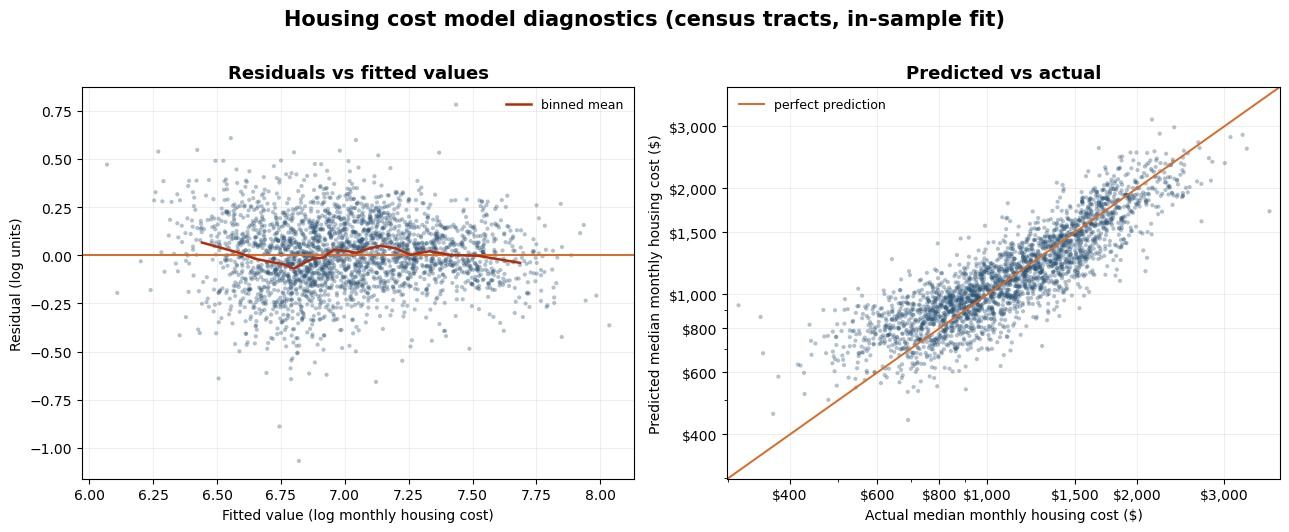

Residual mean: -2.22e-16 (OLS forces this to zero)
Residual skew: -0.237, kurtosis: 1.073
Share of tracts predicted within 10% of actual: 44.9%
Share within 20%: 75.5%


In [251]:
# --- Residual diagnostics ---------------------------------------------------
# Left: residuals against fitted values, to look for curvature or a fan shape.
# Right: predicted against actual dollars, on log-log axes with a 45-degree line.
fitted = final_fit.fittedvalues
residuals = final_fit.resid
actual_dollars = np.exp(y)
predicted_dollars = np.exp(fitted) * final_smearing

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

axes[0].scatter(fitted, residuals, s=9, alpha=.35, color='#254e70', edgecolor='none')
axes[0].axhline(0, color='#d76b29', linewidth=1.4)
# A binned mean traces any systematic curvature the scatter hides.
bins = pd.qcut(fitted, 20, duplicates='drop')
binned = pd.DataFrame({'fitted': fitted, 'resid': residuals}).groupby(bins, observed=True).mean()
axes[0].plot(binned['fitted'], binned['resid'], color='#b02e0c', linewidth=1.8, label='binned mean')
axes[0].set_xlabel('Fitted value (log monthly housing cost)')
axes[0].set_ylabel('Residual (log units)')
axes[0].set_title('Residuals vs fitted values', fontsize=13, fontweight='bold')
axes[0].legend(frameon=False, fontsize=9)

limits = [min(actual_dollars.min(), predicted_dollars.min()) * .95,
          max(actual_dollars.max(), predicted_dollars.max()) * 1.05]
axes[1].scatter(actual_dollars, predicted_dollars, s=9, alpha=.35, color='#254e70', edgecolor='none')
axes[1].plot(limits, limits, color='#d76b29', linewidth=1.4, label='perfect prediction')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlim(limits)
axes[1].set_ylim(limits)
# Plain dollar ticks read better than the default 10^3 on log axes.
dollar_ticks = [400, 600, 800, 1000, 1500, 2000, 3000]
for setter, getter in [(axes[1].set_xticks, axes[1].set_xticklabels),
                       (axes[1].set_yticks, axes[1].set_yticklabels)]:
    setter(dollar_ticks)
    getter([f'${tick:,}' for tick in dollar_ticks])
axes[1].set_xlabel('Actual median monthly housing cost ($)')
axes[1].set_ylabel('Predicted median monthly housing cost ($)')
axes[1].set_title('Predicted vs actual', fontsize=13, fontweight='bold')
axes[1].legend(frameon=False, fontsize=9)

for ax in axes:
    ax.grid(alpha=.25, linewidth=.6)
    ax.set_axisbelow(True)
fig.suptitle('Housing cost model diagnostics (census tracts, in-sample fit)',
             fontsize=15, fontweight='bold')
fig.tight_layout(rect=[0, .02, 1, .97])
fig.savefig(FIG_DIR / 'model_diagnostics_housing_cost.png', dpi=200, bbox_inches='tight')
plt.show()

print(f'Residual mean: {residuals.mean():.2e} (OLS forces this to zero)')
print(f'Residual skew: {residuals.skew():.3f}, kurtosis: {residuals.kurtosis():.3f}')
print(f'Share of tracts predicted within 10% of actual: '
      f'{100 * np.mean(np.abs(predicted_dollars - actual_dollars) / actual_dollars < .10):.1f}%')
print(f'Share within 20%: '
      f'{100 * np.mean(np.abs(predicted_dollars - actual_dollars) / actual_dollars < .20):.1f}%')

**Result: the assumptions hold reasonably well.**

- **Linearity.** The binned mean of the residuals stays flat and close to zero across the fitted range, so there is no curvature calling for a quadratic term or a different transform. The log target was the right choice.
- **Constant variance.** The scatter is an even band rather than a fan, so the log scale fixed the heteroskedasticity that a dollar-scale model would have had.
- **Normality.** Residual skew is −0.237 and excess kurtosis 1.07, so the tails are slightly heavier than normal and there are a few tracts the model badly underpredicts. Mild enough not to threaten the coefficient estimates at n = 2,633, though it argues against reading any single prediction interval too literally.
- **Accuracy.** 44.9% of tracts are predicted within 10% of actual and 75.5% within 20%.

One real limitation: the Durbin-Watson statistic of 1.49 points to **spatial autocorrelation** in the residuals. Neighboring tracts are mis-predicted in the same direction, which is expected for housing data and means the OLS standard errors are somewhat optimistic. The coefficients stay unbiased, and this is exactly why accuracy is quoted from the county-grouped cross-validation rather than from the in-sample fit. A spatial error model would be the next step if inference on individual coefficients mattered more than prediction.
### Predicting every merged zone

The recommender works on merged tract/ZIP zones, so the tract-level model is applied to each zone's own features. A zone inherits its tract's ACS values but keeps its own amenity counts, distances and EPA attributes, so zones inside one tract can receive different predictions. The standardization reuses the training means and standard deviations; rescaling against the zone distribution would silently change what the coefficients mean.

In [252]:
# --- Predict monthly housing cost for every merged zone ---------------------
# The recommender works on the merged tract/ZIP zones, so the tract-level model
# is applied to each zone's own features. The zone keeps its tract's ACS values
# but carries its own amenity counts, distances and EPA attributes, so two zones
# in one tract can receive different predictions.
zone_X = build_features(zone_features)
zone_complete = zone_X[FINAL_FEATURES].notna().all(axis=1)

# Reuse the training means and SDs: a zone must be standardized exactly the way
# the model was fitted, never rescaled against the zone distribution.
zone_scaled, _, _ = standardize(zone_X.loc[zone_complete, FINAL_FEATURES], final_means, final_sds)
zone_prediction = final_fit.get_prediction(sm.add_constant(zone_scaled, has_constant='add'))
prediction_frame = zone_prediction.summary_frame(alpha=.10)  # 90% interval

predicted_log = pd.Series(np.nan, index=zone_features.index, dtype=float)
predicted_log.loc[zone_complete] = prediction_frame['mean'].to_numpy()
lower_log = pd.Series(np.nan, index=zone_features.index, dtype=float)
upper_log = pd.Series(np.nan, index=zone_features.index, dtype=float)
lower_log.loc[zone_complete] = prediction_frame['obs_ci_lower'].to_numpy()
upper_log.loc[zone_complete] = prediction_frame['obs_ci_upper'].to_numpy()

zone_predictions = pd.DataFrame({
    'area_id': zone_features['area_id'],
    'GEOID': zone_features['GEOID'],
    'zcta': zone_features['zcta'],
    'zip': zone_features['zip'],
    'acs_county': zone_features['acs_county'],
    'acs_NAME': zone_features['acs_NAME'],
    'area_sq_km': zone_features['area_sq_km'],
    'predicted_log_housing_cost': predicted_log,
    # Smearing-corrected back-transformation, so this reads as a mean, not a median.
    'predicted_monthly_housing_cost': np.exp(predicted_log) * final_smearing,
    'predicted_cost_low_90': np.exp(lower_log) * final_smearing,
    'predicted_cost_high_90': np.exp(upper_log) * final_smearing,
    # Carried through for reference only; neither was used as a predictor.
    'acs_median_monthly_housing_cost': zone_features['acs_median_monthly_housing_cost'],
    'zillow_home_value': zone_features['zillow_home_value'],
    'has_complete_features': zone_complete,
})
zone_predictions['residual_vs_acs'] = (
    zone_predictions['predicted_monthly_housing_cost']
    - zone_predictions['acs_median_monthly_housing_cost']
)

if zone_predictions['area_id'].duplicated().any() or len(zone_predictions) != len(zone_features):
    raise ValueError('Zone predictions must stay one row per area_id.')

OUTPUT_PATH = PROCESSED_DIR / 'zone_predicted_housing_cost.csv'
zone_predictions.to_csv(OUTPUT_PATH, index=False)

print(f'Saved {len(zone_predictions):,} zone predictions to {OUTPUT_PATH.name}')
print(f'Predictions produced: {int(zone_complete.sum()):,} '
      f'({100 * zone_complete.mean():.1f}% of zones); '
      f'{int((~zone_complete).sum()):,} left missing for incomplete features')
display(zone_predictions['predicted_monthly_housing_cost'].describe().round(0).to_frame('predicted_$'))
display(zone_predictions.head(5))

Saved 5,466 zone predictions to zone_predicted_housing_cost.csv
Predictions produced: 5,415 (99.1% of zones); 51 left missing for incomplete features


,predicted_$
count,5415.0
mean,1131.0
std,388.0
min,438.0
25%,858.0
50%,1026.0
75%,1305.0
max,3157.0


,area_id,GEOID,zcta,zip,acs_county,acs_NAME,area_sq_km,predicted_log_housing_cost,predicted_monthly_housing_cost,predicted_cost_low_90,predicted_cost_high_90,acs_median_monthly_housing_cost,zillow_home_value,has_complete_features,residual_vs_acs
0,37001020100_27215,37001020100,27215,27215,1,Census Tract 201; Alamance County; North Carolina,4.061674,6.972643,1084.403721,804.354443,1461.956779,1059.0,293570.844649,True,25.403721
1,37001020100_27217,37001020100,27217,27217,1,Census Tract 201; Alamance County; North Carolina,0.449831,6.980823,1093.309746,810.803107,1474.249653,1059.0,222551.157966,True,34.309746
2,37001020200_27217,37001020200,27217,27217,1,Census Tract 202; Alamance County; North Carolina,3.464568,6.542225,705.119380,522.755572,951.100986,694.0,222551.157966,True,11.119380
3,37001020301_27217,37001020301,27217,27217,1,Census Tract 203.01; Alamance County; North Ca...,5.025703,6.959510,1070.254924,793.835613,1442.925442,920.0,222551.157966,True,150.254924
4,37001020302_27217,37001020302,27217,27217,1,Census Tract 203.02; Alamance County; North Ca...,4.276168,6.753399,870.912144,645.907933,1174.297331,935.0,222551.157966,True,-64.087856


**Result.** Predictions were produced for **5,415 of 5,466 zones (99.1%)**. The 51 without one are missing a source input, not a prediction step: all 51 lack tract median household income, and 24 of those also lack the EPA attributes. They are written out with a null prediction and `has_complete_features = False` rather than filled in, so the recommender can skip them deliberately instead of ranking a guess.

Predicted costs run from $438 to $3,157 per month, median $1,026, against an observed zone-level range of $315 to $3,703 with median $1,024. The prediction range is narrower than the observed one, which is the expected behavior of a regression: it shrinks toward the mean and does not reproduce the extremes.

Zones inside the same tract receive different predictions, since each carries its own amenity counts, distances and EPA attributes even though the ACS inputs are shared. The two Alamance County zones in the preview above differ by about $9 a month, which is a reasonable magnitude: the share of the prediction driven by zone-varying features is small next to income.

`zone_predicted_housing_cost.csv` contains, for each `area_id`: the predicted cost in dollars and in log units, a 90% prediction interval, the tract's observed ACS cost and the ZIP's Zillow value for reference, and the completeness flag. The interval is wide, roughly ±35%, because it covers the spread of individual tracts around the fit rather than uncertainty in the average.
### Checking the predictions against Zillow

Zillow was never used as a predictor, which makes it a genuinely independent check on whether the predictions order areas sensibly.

In [253]:
# --- Sanity check against the Zillow values ---------------------------------
# Zillow reports a ZIP-level home *value* and the model predicts a tract-level
# monthly *cost*, so the levels are not comparable and only the agreement in
# ranking is meaningful. The fair benchmark is how well the observed ACS cost
# itself tracks Zillow: the model should come close to that, not beat it.
check = zone_predictions.join(zone_features['zillow_home_value'].rename('zillow'), how='left')
check = check[['predicted_monthly_housing_cost', 'acs_median_monthly_housing_cost', 'zillow']]
check.columns = ['predicted', 'acs_actual', 'zillow']
paired = check.dropna()

correlations = pd.DataFrame({
    'pearson': [paired['predicted'].corr(paired['zillow']),
                paired['acs_actual'].corr(paired['zillow']),
                paired['predicted'].corr(paired['acs_actual'])],
    'spearman': [paired['predicted'].corr(paired['zillow'], method='spearman'),
                 paired['acs_actual'].corr(paired['zillow'], method='spearman'),
                 paired['predicted'].corr(paired['acs_actual'], method='spearman')],
}, index=['predicted cost vs Zillow value',
          'observed ACS cost vs Zillow value',
          'predicted cost vs observed ACS cost']).round(4)
display(correlations)

# Agreement by Zillow decile: both series should climb together.
paired = paired.assign(zillow_decile=pd.qcut(paired['zillow'], 10, labels=False) + 1)
by_decile = paired.groupby('zillow_decile').agg(
    zones=('zillow', 'size'),
    median_zillow_value=('zillow', 'median'),
    median_predicted_cost=('predicted', 'median'),
    median_actual_cost=('acs_actual', 'median'),
).round(0)
display(by_decile)

ratio = (paired['zillow'] / paired['predicted'])
print(f'Zones with both a prediction and a Zillow value: {len(paired):,}')
print(f'Rank agreement with Zillow: model {paired["predicted"].corr(paired["zillow"], method="spearman"):.3f} '
      f'vs observed ACS cost {paired["acs_actual"].corr(paired["zillow"], method="spearman"):.3f}')
print(f'Implied value-to-monthly-cost ratio: median {ratio.median():,.0f}x '
      f'(interquartile {ratio.quantile(.25):,.0f}x to {ratio.quantile(.75):,.0f}x)')
print(f'Predicted cost rises across Zillow deciles: '
      f'${by_decile["median_predicted_cost"].iloc[0]:,.0f} in the cheapest decile to '
      f'${by_decile["median_predicted_cost"].iloc[-1]:,.0f} in the most expensive')

,pearson,spearman
predicted cost vs Zillow value,0.6541,0.6730
observed ACS cost vs Zillow value,0.6361,0.6648
predicted cost vs observed ACS cost,0.8799,0.8641


,zones,median_zillow_value,median_predicted_cost,median_actual_cost
zillow_decile,,,,
1,536,138450.0,768.0,745.0
2,524,201617.0,871.0,830.0
3,517,230180.0,907.0,858.0
4,541,261392.0,936.0,892.0
5,501,287987.0,985.0,944.0
6,529,316420.0,1080.0,1100.0
7,525,348330.0,1173.0,1222.0
8,519,401150.0,1243.0,1310.0
9,541,469579.0,1364.0,1447.0


Zones with both a prediction and a Zillow value: 5,238
Rank agreement with Zillow: model 0.673 vs observed ACS cost 0.665
Implied value-to-monthly-cost ratio: median 281x (interquartile 228x to 337x)
Predicted cost rises across Zillow deciles: $768 in the cheapest decile to $1,770 in the most expensive


**Result: the predictions pass the sanity check.**

The right comparison is not whether the predictions match Zillow in level. Zillow reports a **ZIP-level home value** and the model predicts a **tract-level monthly cost** across all tenures, so the two are in different units for different geographies, and the implied median ratio of 281x simply reflects that a house costs a few hundred times its monthly housing payment. Only the agreement in ranking carries information.

The benchmark is how well the **observed** ACS cost tracks Zillow, because the model cannot be expected to beat the real data it was fitted to:

| Comparison | Spearman |
|---|---|
| Predicted cost vs Zillow value | **0.673** |
| Observed ACS cost vs Zillow value | 0.665 |
| Predicted cost vs observed ACS cost | 0.864 |

The model's agreement with Zillow (0.673) **matches what the observed ACS values achieve (0.665)**. The predictions line up with an independent commercial source as well as the survey data does, which is the result this check was meant to find. That the predicted figure edges out the observed one is not an improvement on reality; it reflects the model smoothing away ACS sampling noise in small tracts, which happens to move it slightly closer to Zillow's ZIP-level aggregates.

Median predicted cost also rises monotonically across all ten Zillow deciles, from $768 in the cheapest to $1,770 in the most expensive, tracking the observed series ($745 to $1,717) closely at every step. There is no decile where the model inverts the market ordering.

Two caveats carry forward to the recommender: 3.4% of zones have no Zillow value, so this check does not cover them; and the two sources describe different years and different housing universes, so the agreement in ranking should not be read as agreement about any particular area's cost.

### Summary and limits

The model explains about three quarters of the variation in median monthly housing cost across North Carolina census tracts (CV R² 0.749), predicting a typical tract within roughly 12%. Income alone would manage half that; the location features — amenity access, walkability, tenure mix, car dependence and metro proximity — carry the rest, which is what justifies using them in a recommender.

Carry these limits into the write-up:

- **Correlational, not causal.** These are associations among features measured at different times. Nothing here says that adding a park to a tract would raise its housing costs.
- **Spatial autocorrelation** remains in the residuals, so the reported standard errors are optimistic. Significance claims about individual coefficients should stay cautious.
- **Mixed vintages.** ACS 2020-2024 estimates, 2010-based EPA attributes, current OSM extracts and a separate Zillow vintage are combined in one model.
- **Distance to passenger rail does not belong in a causal story**, and distance to the airport is standing in for metro centrality.
- **Ecological inference.** Tract medians describe tracts, not households. A tract's predicted cost is not what any particular household will pay.

# Recommender features

Five tract-level feature groups for the recommender, added to the saved feature table. These describe **who a place suits** rather than what it costs: how far it is from a city the user picks, whether it is urban or rural, what kinds of households and homes are there, how the nearby schools perform, and how close a hospital is.

**Unit of analysis.** Everything is built once per census tract (2,661 of them) and joined onto the existing zones on the 11-digit tract `GEOID`. The tract values then repeat across the zones inside a tract, exactly as the existing ACS and EPA columns already do.

**Reference point.** Each tract is represented by the TIGER internal point (`INTPTLAT`/`INTPTLON`), which is guaranteed to fall inside the tract even when the shape is irregular. That is the same idea as the `representative_point()` the amenity section uses for zones.

**Sources and vintages.** Each download is cached under `data/raw/`, in a themed subfolder, and is never fetched twice.

| Feature group | Source | Vintage | Download |
|---|---|---|---|
| Distance to 8 city centers | Coordinates written into the notebook | — | none |
| Urban / suburban / rural | USDA ERS RUCA, census tracts | 2020 codes | ~25 MB |
| Household and bedroom mix | Census ACS 5-year | 2020-2024 | API, or ~100 MB summary file |
| Schools and performance grades | NCES EDGE + NCES CCD + NC DPI | 2023-24 / 2024-25 | ~245 MB |
| Hospitals | OpenStreetMap extract already in `data/` | current extract | none |

The first run downloads roughly 370 MB. Later runs reuse the cache.

**What is written.** The existing `nc_housing_features.csv` gains the new columns with every original column intact, and the tract-level table is also saved on its own as `nc_tract_recommender_features.csv`. The regression section is untouched.

### One row per tract

The saved feature table has one row per merged tract/ZIP zone, so a tract can appear up to seven times. Building these features per zone would repeat identical work and invite inconsistencies, so the tract list is deduplicated first, given a reference point, and projected once into the notebook's working CRS (`EPSG:32119`, meters) for all the distance and count work that follows.

In [254]:
# --- Setup for the recommender-feature section ------------------------------
# Self-contained like the modeling section: it reloads the saved feature table
# so it can be run on its own after a kernel restart.
from pathlib import Path
import io
import os
import zipfile

import numpy as np
import pandas as pd
import geopandas as gpd
import pyogrio
import requests
from scipy.spatial import cKDTree
from IPython.display import display

if 'PROCESSED_DIR' not in globals():
    PROJECT_DIR = Path.cwd()
    DATA_DIR = PROJECT_DIR / 'data'
    PROCESSED_DIR = DATA_DIR / 'processed'
    PROJECT_CRS = 'EPSG:32119'
    OSM_PATH = DATA_DIR / 'north-carolina.gpkg'
    pd.set_option('display.max_columns', 50)

# Downloads are cached under data/raw, in themed subfolders, the same way the
# TIGER boundaries already are. Nothing is re-downloaded once it is on disk.
RAW_DIR = DATA_DIR / 'raw'
BOUNDARY_DIR = RAW_DIR / 'boundaries'
RUCA_DIR = RAW_DIR / 'ruca'
SCHOOL_DIR = RAW_DIR / 'schools'
ACS_SF_DIR = RAW_DIR / 'acs_summary_file'
for folder in [RUCA_DIR, SCHOOL_DIR, ACS_SF_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Some agency servers reject requests without a browser-style user agent, and
# NC DPI additionally requires the referring page, so headers are passed here.
# This mirrors download_cached() in the shared setup, with headers added.
def download_cached(url, path, headers=None):
    """Download once and reuse the cached copy on later runs."""
    path = Path(path)
    if path.exists():
        return path
    path.parent.mkdir(parents=True, exist_ok=True)
    temporary = path.with_suffix(path.suffix + '.part')
    print('Downloading:', path.name)
    with requests.get(url, stream=True, timeout=(30, 300), headers=headers or {}) as response:
        response.raise_for_status()
        with temporary.open('wb') as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)
    temporary.replace(path)
    print(f'  saved {path.stat().st_size / 1e6:,.1f} MB')
    return path


AGENCY_HEADERS = {'User-Agent': 'Mozilla/5.0 (NC housing research project)'}

FEATURES_CSV = PROCESSED_DIR / 'nc_housing_features.csv'
TRACT_BOUNDARY_ZIP = BOUNDARY_DIR / 'tl_2024_37_tract.zip'
for required in [FEATURES_CSV, TRACT_BOUNDARY_ZIP]:
    if not required.exists():
        raise FileNotFoundError(f'Missing {required}. Run the earlier sections first.')

ID_DTYPES = {'GEOID': str, 'zcta': str, 'zip': str, 'epa_tract': str, 'area_id': str}
zone_features = pd.read_csv(FEATURES_CSV, dtype=ID_DTYPES)
original_columns = list(zone_features.columns)

print(f'Existing feature table: {len(zone_features):,} zones x {len(original_columns)} columns')
print(f'Distinct census tracts: {zone_features["GEOID"].nunique():,}')
print('Download cache:', RAW_DIR)

Existing feature table: 5,466 zones x 53 columns
Distinct census tracts: 2,661
Download cache: /Users/josiah/2302GroupProj/2302-group-proj/data/raw


In [255]:
# --- One row per census tract, with a reference point -----------------------
# Every new feature is tract-level, so the work is done once per tract and
# joined back to the zones at the end. The 11-digit GEOID is the join key.
tract_base = (
    zone_features[['GEOID', 'acs_county', 'acs_NAME']]
    .drop_duplicates('GEOID')
    .sort_values('GEOID')
    .reset_index(drop=True)
)

# TIGER publishes an internal point (INTPTLAT/INTPTLON) that is guaranteed to
# fall inside the tract, which is safer than a centroid for irregular shapes.
tract_points = pyogrio.read_dataframe(
    f'zip://{TRACT_BOUNDARY_ZIP}',
    read_geometry=False,
    columns=['GEOID', 'INTPTLAT', 'INTPTLON'],
)
tract_points['lat'] = tract_points['INTPTLAT'].astype(float)
tract_points['lon'] = tract_points['INTPTLON'].astype(float)

tract_base = tract_base.merge(
    tract_points[['GEOID', 'lat', 'lon']], on='GEOID', how='left', validate='one_to_one'
)
if tract_base[['lat', 'lon']].isna().any().any():
    raise ValueError('A tract did not receive a reference point from the TIGER file.')

# Projected copy in meters, reused by every distance and count below. This is
# the same CRS the notebook already uses for amenity distances.
tract_geo = gpd.GeoDataFrame(
    tract_base[['GEOID']],
    geometry=gpd.points_from_xy(tract_base['lon'], tract_base['lat']),
    crs='EPSG:4269',
).to_crs(PROJECT_CRS)
tract_xy = np.c_[tract_geo.geometry.x, tract_geo.geometry.y]

print(f'Tract table: {len(tract_base):,} rows, one per GEOID')
display(tract_base.head(3))

Tract table: 2,661 rows, one per GEOID


,GEOID,acs_county,acs_NAME,lat,lon
0,37001020100,1,Census Tract 201; Alamance County; North Carolina,36.091477,-79.445599
1,37001020200,1,Census Tract 202; Alamance County; North Carolina,36.091910,-79.419540
2,37001020301,1,Census Tract 203.01; Alamance County; North Ca...,36.106543,-79.405574


### Feature 1: distance to a user-chosen city

The recommender lets someone say "within an hour of Raleigh", so every tract carries its distance to each of the eight largest NC city centers as `dist_km_<city>`. Distances are great-circle (haversine) kilometers from the tract's internal point to an approximate downtown coordinate.

Two caveats worth carrying into the recommender: these are **straight-line** distances, not drive times, which matters most in the mountains where road distance far exceeds straight-line distance; and a single downtown point stands in for a whole metro, so a tract in a western Wake County suburb is measured to downtown Raleigh rather than to the nearest edge of the built-up area.

In [256]:
# --- Feature 1: distance to each major NC city ------------------------------
# Approximate downtown/city-center coordinates. No download needed. These are
# reference points for ranking, not precise municipal boundaries.
NC_CITY_CENTERS = {
    'Charlotte':     (35.2271, -80.8431),
    'Raleigh':       (35.7796, -78.6382),
    'Durham':        (35.9940, -78.8986),
    'Greensboro':    (36.0726, -79.7920),
    'Winston-Salem': (36.0999, -80.2442),
    'Fayetteville':  (35.0527, -78.8784),
    'Wilmington':    (34.2257, -77.9447),
    'Asheville':     (35.5951, -82.5515),
}


def haversine_km(lat1, lon1, lat2, lon2, earth_radius_km=6371.0088):
    """Great-circle distance in km between two points given in degrees."""
    phi1, phi2 = np.radians(lat1), np.radians(lat2)
    delta_phi = phi2 - phi1
    delta_lambda = np.radians(lon2) - np.radians(lon1)
    a = np.sin(delta_phi / 2) ** 2 + np.cos(phi1) * np.cos(phi2) * np.sin(delta_lambda / 2) ** 2
    return 2 * earth_radius_km * np.arcsin(np.sqrt(a))


city_distance_columns = []
for city, (city_lat, city_lon) in NC_CITY_CENTERS.items():
    # Column names are lowercased with underscores: Winston-Salem -> winston_salem.
    column = 'dist_km_' + city.lower().replace('-', '_').replace(' ', '_')
    tract_base[column] = haversine_km(
        tract_base['lat'].to_numpy(), tract_base['lon'].to_numpy(), city_lat, city_lon
    ).round(3)
    city_distance_columns.append(column)

# Convenience columns so the recommender can rank without recomputing.
tract_base['nearest_major_city'] = (
    tract_base[city_distance_columns].idxmin(axis=1).str.replace('dist_km_', '', regex=False)
)
tract_base['dist_km_nearest_major_city'] = tract_base[city_distance_columns].min(axis=1).round(3)

display(tract_base[city_distance_columns].describe().round(1))
print('Tracts closest to each city:')
display(tract_base['nearest_major_city'].value_counts().rename('tracts').to_frame())

,dist_km_charlotte,dist_km_raleigh,dist_km_durham,dist_km_greensboro,dist_km_winston_salem,dist_km_fayetteville,dist_km_wilmington,dist_km_asheville
count,2661.0,2661.0,2661.0,2661.0,2661.0,2661.0,2661.0,2661.0
mean,160.3,157.6,154.8,146.8,153.0,160.4,243.8,270.0
std,104.4,97.0,91.0,81.8,87.5,83.2,106.1,137.1
min,0.4,0.2,0.7,0.6,0.2,0.9,0.5,0.2
25%,76.4,83.7,87.8,94.7,98.6,102.7,172.7,161.9
50%,158.6,155.2,153.0,133.9,132.2,153.7,257.7,257.5
75%,221.8,210.3,207.0,194.3,212.9,191.6,298.0,363.1
max,478.7,514.4,494.9,418.3,432.1,488.7,584.0,633.4


Tracts closest to each city:


,tracts
nearest_major_city,
charlotte,667
raleigh,547
asheville,268
wilmington,261
winston_salem,253
fayetteville,252
greensboro,222
durham,191


**Result.** Eight distance columns, no missing values. Charlotte is the closest city for 667 tracts and Raleigh for 547, which together account for 46% of the state; Durham claims only 191 because Raleigh sits so close to it that it wins most of the Triangle. The minimum distance for each city is under a kilometer, confirming the coordinates land in the right downtown.

The maximum distances are large on purpose: 633 km from Asheville to the far Outer Banks. North Carolina is about 800 km end to end, so a single "distance to city" column would be useless statewide. Keeping all eight lets the recommender answer "near Asheville" and "near Wilmington" as genuinely different questions.

### Feature 2: urban, suburban or rural

USDA ERS Rural-Urban Commuting Area codes classify each tract by **where its workers actually commute**, not by population density alone, which is why a dense small town surrounded by farmland is not mistaken for a suburb. The 2020 codes are built on 2020 census tracts, matching the tract vintage used everywhere else in this notebook.

The ten primary codes are collapsed as the project specified: 1-3 urban, 4-6 suburban/small town, 7-10 rural. Code 99 means the tract has no population or no commuting data; those tracts are left missing rather than forced into a bucket.

In [257]:
# --- Feature 2: urban / suburban / rural from USDA ERS 2020 RUCA ------------
# RUCA classifies tracts by commuting flows, which is a better settlement
# measure than population density alone. The 2020 codes use 2020 census tracts,
# matching the vintage of the ACS tract boundaries used throughout.
RUCA_URL = ('https://www.ers.usda.gov/media/5443/'
            '2020-rural-urban-commuting-area-codes-census-tracts.csv?v=29223')
ruca_path = download_cached(RUCA_URL, RUCA_DIR / 'ruca_2020_census_tracts.csv',
                            headers=AGENCY_HEADERS)

# The national file carries non-UTF-8 place names, so it is read as latin-1.
ruca_raw = pd.read_csv(ruca_path, dtype=str, encoding='latin-1')
ruca_nc = ruca_raw[ruca_raw['StateFIPS20'] == '37'].copy()
ruca_nc['ruca_primary_code'] = pd.to_numeric(ruca_nc['PrimaryRUCA'], errors='coerce')


def ruca_setting(code):
    """Collapse the 10 primary RUCA codes into three settlement types.

    Code 99 means the tract has no population or no commuting data, so it is
    left missing rather than forced into a category.
    """
    if pd.isna(code) or code >= 99:
        return pd.NA
    if code <= 3:
        return 'urban'
    if code <= 6:
        return 'suburban/small town'
    return 'rural'


ruca_nc['setting_type'] = ruca_nc['ruca_primary_code'].map(ruca_setting)

tract_base = tract_base.merge(
    ruca_nc[['TractFIPS20', 'ruca_primary_code', 'setting_type']]
    .rename(columns={'TractFIPS20': 'GEOID'}),
    on='GEOID', how='left', validate='one_to_one',
)

print(f'RUCA rows for North Carolina: {len(ruca_nc):,}')
print(f'Tracts matched: {tract_base["ruca_primary_code"].notna().sum():,} of {len(tract_base):,}')
display(
    tract_base.groupby('setting_type', dropna=False)
    .agg(tracts=('GEOID', 'size'))
    .assign(pct=lambda d: (100 * d['tracts'] / len(tract_base)).round(1))
)

RUCA rows for North Carolina: 2,672
Tracts matched: 2,661 of 2,661


,tracts,pct
setting_type,,
rural,299,11.2
suburban/small town,431,16.2
urban,1929,72.5
NaN,2,0.1


**Result.** All 2,661 tracts matched the RUCA file on the 11-digit GEOID, with no fallback needed.

| Setting | Tracts | Share |
|---|---|---|
| Urban | 1,929 | 72.5% |
| Suburban / small town | 431 | 16.2% |
| Rural | 299 | 11.2% |
| Unclassified (RUCA 99) | 2 | 0.1% |

Worth flagging before anyone quotes these: **72.5% urban describes tracts, not land**. Tracts are drawn to hold roughly equal population, so urban tracts are small and numerous while rural tracts are large and few. North Carolina is not 72.5% urban by area, and the two unclassified tracts are zero-population.

This also means the recommender should not treat "rural" as a rare category. 299 tracts is a substantial set of places, just spread across most of the state's land.

### Feature 3: household fit

Four measures of who lives in a tract and what the housing stock looks like, from the same ACS 2020-2024 5-year release the rest of the notebook uses:

- **Median age** (`B01002_001`)
- **Average household size** (`B25010_001`)
- **Share of households with children under 18** (`B11005_002 / B11005_001`)
- **Bedroom mix** (`B25041`), as four shares: 0-1, 2, 3, and 4+ bedrooms

One practical change from section 2: the Census API now **rejects tract requests that do not carry an API key**, where it used to allow a daily allowance of keyless calls. So this cell takes the API route when `CENSUS_API_KEY` is set, and otherwise falls back to the Census table-based Summary File, which needs no key and publishes the identical estimates from the same release. The printed line says which route ran.

ACS "not available" codes are all large negative jam values, and they are masked to missing exactly as section 2 does, before any share is computed. The four bedroom shares partition one denominator, so the cell asserts they sum to 1.

In [258]:
# --- Feature 3: household-fit measures from ACS 2020-2024 5-year ------------
# Same release the rest of the notebook uses (ACS 5-year, YEAR = 2024).
# Two routes to the same estimates:
#   * the Census API, the approach used in section 2, when CENSUS_API_KEY is set;
#   * otherwise the Census table-based Summary File, which needs no key.
# The API now rejects keyless tract requests, so the fallback keeps this cell
# runnable for teammates who have not requested a key yet.
ACS_YEAR = 2024
ACS_VARIABLES = {
    'B01002_001': 'acs_median_age',              # Median age
    'B25010_001': 'acs_avg_household_size',      # Average household size, occupied units
    'B11005_001': '_households_total',           # Households
    'B11005_002': '_households_with_children',   # Households with people under 18
    'B25041_001': '_bedrooms_total',             # Units by bedroom count
    'B25041_002': '_bedrooms_0',
    'B25041_003': '_bedrooms_1',
    'B25041_004': '_bedrooms_2',
    'B25041_005': '_bedrooms_3',
    'B25041_006': '_bedrooms_4',
    'B25041_007': '_bedrooms_5plus',
}

census_key = os.environ.get('CENSUS_API_KEY', '')


def fetch_acs_from_api(variables, year, key):
    """Tract-level pull from the Census API, as in section 2."""
    url = f'https://api.census.gov/data/{year}/acs/acs5'
    params = [
        ('get', ','.join(f'{v}E' for v in variables)),
        ('for', 'tract:*'), ('in', 'state:37'), ('in', 'county:*'), ('key', key),
    ]
    response = requests.get(url, params=params, timeout=120)
    response.raise_for_status()
    rows = response.json()
    frame = pd.DataFrame(rows[1:], columns=rows[0])
    frame['GEOID'] = frame['state'] + frame['county'] + frame['tract']
    return frame.rename(columns={f'{v}E': v for v in variables})[['GEOID', *variables]]


def fetch_acs_from_summary_file(variables, year):
    """Same estimates from the table-based Summary File, no API key required."""
    frames = []
    for table in sorted({v.split('_')[0].lower() for v in variables}):
        url = (f'https://www2.census.gov/programs-surveys/acs/summary_file/{year}/'
               f'table-based-SF/data/5YRData/acsdt5y{year}-{table}.dat')
        path = download_cached(url, ACS_SF_DIR / f'acsdt5y{year}-{table}.dat')
        raw = pd.read_csv(path, sep='|', dtype=str)
        # Summary-file GEO_IDs look like 1400000US37001020100; 1400000US = tract.
        raw = raw[raw['GEO_ID'].str.startswith('1400000US37')].copy()
        wanted = {}
        for variable in variables:
            table_name, sequence = variable.split('_')
            if table_name.lower() != table:
                continue
            # Summary-file columns are B01002_E001, the API uses B01002_001E.
            wanted[variable] = raw[f'{table_name}_E{sequence}'].to_numpy()
        frames.append(pd.DataFrame({'GEOID': raw['GEO_ID'].str[-11:].to_numpy(), **wanted}))
    merged = frames[0]
    for frame in frames[1:]:
        merged = merged.merge(frame, on='GEOID', how='outer')
    return merged


if census_key:
    print('CENSUS_API_KEY found: using the Census API.')
    acs_raw = fetch_acs_from_api(list(ACS_VARIABLES), ACS_YEAR, census_key)
else:
    print('No CENSUS_API_KEY set: using the Census Summary File (same ACS release).')
    acs_raw = fetch_acs_from_summary_file(list(ACS_VARIABLES), ACS_YEAR)

acs = acs_raw.rename(columns=ACS_VARIABLES)
for column in ACS_VARIABLES.values():
    numeric = pd.to_numeric(acs[column], errors='coerce')
    # ACS "not available" jam values are all negative, as handled in section 2.
    acs[column] = numeric.mask(numeric < 0)

# Shares, guarding against a zero denominator in tracts with no households.
households = acs['_households_total'].replace(0, np.nan)
acs['acs_share_households_with_children'] = (acs['_households_with_children'] / households).round(4)

units = acs['_bedrooms_total'].replace(0, np.nan)
acs['acs_share_units_0_1_bedroom'] = ((acs['_bedrooms_0'] + acs['_bedrooms_1']) / units).round(4)
acs['acs_share_units_2_bedroom'] = (acs['_bedrooms_2'] / units).round(4)
acs['acs_share_units_3_bedroom'] = (acs['_bedrooms_3'] / units).round(4)
acs['acs_share_units_4plus_bedroom'] = ((acs['_bedrooms_4'] + acs['_bedrooms_5plus']) / units).round(4)

acs_feature_columns = [
    'acs_median_age', 'acs_avg_household_size', 'acs_share_households_with_children',
    'acs_share_units_0_1_bedroom', 'acs_share_units_2_bedroom',
    'acs_share_units_3_bedroom', 'acs_share_units_4plus_bedroom',
]
bedroom_columns = [c for c in acs_feature_columns if 'bedroom' in c]

# The four bedroom shares partition the same denominator, so they must sum to 1.
share_total = acs[bedroom_columns].sum(axis=1, min_count=len(bedroom_columns))
if share_total.dropna().sub(1).abs().max() > 0.01:
    raise ValueError('Bedroom shares do not sum to 1; check the B25041 line numbers.')

tract_base = tract_base.merge(
    acs[['GEOID', *acs_feature_columns]], on='GEOID', how='left', validate='one_to_one'
)
print(f'ACS rows pulled: {len(acs):,}; bedroom shares sum to 1 within rounding.')
display(tract_base[acs_feature_columns].describe().round(3))

No CENSUS_API_KEY set: using the Census Summary File (same ACS release).
ACS rows pulled: 2,672; bedroom shares sum to 1 within rounding.


,acs_median_age,acs_avg_household_size,acs_share_households_with_children,acs_share_units_0_1_bedroom,acs_share_units_2_bedroom,acs_share_units_3_bedroom,acs_share_units_4plus_bedroom
count,2647.000,2638.000,2640.000,2640.000,2640.000,2640.000,2640.000
mean,40.900,2.436,0.286,0.087,0.240,0.469,0.204
std,8.183,0.360,0.102,0.103,0.126,0.158,0.149
min,19.300,1.320,0.000,0.000,0.000,0.000,0.000
25%,35.400,2.200,0.224,0.018,0.151,0.363,0.105
50%,40.500,2.430,0.282,0.051,0.233,0.488,0.165
75%,45.700,2.670,0.348,0.119,0.316,0.586,0.257
max,72.400,4.160,0.758,0.705,1.000,1.000,0.935


**Result.** The summary-file route ran, since no `CENSUS_API_KEY` is set in this environment, pulling the four tables for all 2,672 NC tracts. The bedroom shares passed the sum-to-one assertion.

The distributions look like North Carolina: median age 40.5 years at the median tract (ranging from 19.3 in a campus tract to 72.4 in a retirement area), average household size 2.43, and 28.2% of households with children. The bedroom mix is dominated by three-bedroom houses (46.9% of units on average), with only 8.7% of units having 0-1 bedrooms, which is a useful signal that single-person renters have genuinely limited options in most tracts.

Missing values are confined to tracts with no one in them: 14 tracts lack median age (11 of them zero-population), and 23 lack average household size (21 of them report zero occupied units). All 23 already lacked the housing-cost target used in the regression section, so these gaps remove nothing the model could have used.

### Feature 4: schools and performance grades

This is the only feature that needs three files, because **no single published file carries both a school's location and its North Carolina performance grade**:

1. **NCES EDGE geocodes (2023-24)** give each public school a coordinate, keyed by the 12-digit federal `NCESSCH`.
2. **NC DPI School Report Card** gives the A-F School Performance Grade, keyed by the six-digit DPI `agency_code`.
3. The two IDs do not overlap, so the **NCES CCD directory (2023-24)** supplies the bridge: its `ST_SCHID` field is written `NC-260-308`, and stripping the prefix and dashes yields the DPI code `260308`.

Grades convert to points as A=4, B=3, C=2, D=1, F=0. Two tract measures are computed: the **count of schools within 5 km** and the **average grade points of the nearest 3 schools**.

The two measures treat unmatched schools differently, on purpose. The **count** includes every located public school, graded or not, because an ungraded school is still a school. The **grade average** is taken over graded schools only, so the three nearest *graded* schools are used; an ungraded school is skipped rather than counted as a zero, which would otherwise punish tracts near new or alternative schools. `mean_dist_km_nearest_3_schools` is reported alongside so a tract whose "nearest three" are far away can be spotted and discounted.

In [259]:
# --- Feature 4: public schools and performance grades -----------------------
# Three files are needed, because no single file carries both the school
# location and the NC performance grade:
#   1. NCES EDGE geocodes  -> school coordinates, keyed by the 12-digit NCESSCH.
#   2. NCES CCD directory  -> ST_SCHID ("NC-260-308"), the bridge to the DPI code.
#   3. NC DPI report card  -> School Performance Grade, keyed by DPI agency_code.
# EDGE and CCD are both 2023-24; the DPI grades are the most recent release.
EDGE_URL = 'https://nces.ed.gov/programs/edge/data/EDGE_GEOCODE_PUBLICSCH_2324.zip'
CCD_URL = 'https://nces.ed.gov/ccd/Data/zip/ccd_sch_029_2324_w_1a_073124.zip'
DPI_SRC_URL = 'https://www.dpi.nc.gov/src-data-set-2024-251-2/open'
DPI_HEADERS = {
    **AGENCY_HEADERS,
    'Referer': ('https://www.dpi.nc.gov/data-reports/school-report-cards/'
                'school-report-card-resources-researchers'),
}

edge_zip = download_cached(EDGE_URL, SCHOOL_DIR / 'EDGE_GEOCODE_PUBLICSCH_2324.zip',
                           headers=AGENCY_HEADERS)
ccd_zip = download_cached(CCD_URL, SCHOOL_DIR / 'ccd_sch_029_2324_w_1a_073124.zip',
                          headers=AGENCY_HEADERS)
# ~200 MB: the NC School Report Card research release, downloaded once.
dpi_zip = download_cached(DPI_SRC_URL, SCHOOL_DIR / 'src_datasets_2425_1_of_2.zip',
                          headers=DPI_HEADERS)

# 1. School locations, read straight out of the zipped shapefile.
schools = pyogrio.read_dataframe(
    f'zip://{edge_zip}!EDGE_GEOCODE_PUBLICSCH_2324/Shapefiles_SCH/EDGE_GEOCODE_PUBLICSCH_2324.shp',
    where="STATE='NC'",
)
located = schools['LAT'].notna() & schools['LON'].notna() & schools['LAT'].ne(0)
print(f'NCES schools in NC: {len(schools):,} ({(~located).sum()} without usable coordinates)')
schools = schools.loc[located, ['NCESSCH', 'NAME', 'geometry']].copy()

# 2. Crosswalk. ST_SCHID is "NC-260-308"; the DPI code is the digits, "260308".
with zipfile.ZipFile(ccd_zip) as archive:
    ccd_name = next(n for n in archive.namelist() if n.lower().endswith('.csv'))
    directory = pd.read_csv(io.BytesIO(archive.read(ccd_name)), dtype=str, encoding='latin-1',
                            usecols=['ST', 'NCESSCH', 'ST_SCHID'], low_memory=False)
directory = directory[directory['ST'] == 'NC'].copy()
directory['dpi_code'] = directory['ST_SCHID'].str.replace('NC-', '', regex=False).str.replace('-', '', regex=False)

# 3. Performance grades: most recent year, all-students subgroup.
with zipfile.ZipFile(dpi_zip) as archive:
    spg_name = next(n for n in archive.namelist() if n.endswith('rcd_acc_spg2.xlsx'))
    grades_raw = pd.read_excel(io.BytesIO(archive.read(spg_name)), dtype=str)
latest_year = max(grades_raw['year'])
grades = grades_raw[(grades_raw['year'] == latest_year) & (grades_raw['subgroup'] == 'ALL')].copy()

GRADE_POINTS = {'A': 4.0, 'A+NG': 4.0, 'B': 3.0, 'C': 2.0, 'D': 1.0, 'F': 0.0}
grades['grade_points'] = grades['spg_grade'].str.strip().str.upper().map(GRADE_POINTS)

schools = (
    schools.merge(directory[['NCESSCH', 'dpi_code']], on='NCESSCH', how='left')
           .merge(grades[['agency_code', 'spg_grade', 'grade_points']],
                  left_on='dpi_code', right_on='agency_code', how='left')
)

school_match = pd.DataFrame({
    'stage': ['located NCES schools', 'matched to a DPI code', 'matched to a performance grade'],
    'schools': [len(schools), int(schools['dpi_code'].notna().sum()),
                int(schools['grade_points'].notna().sum())],
})
school_match['pct_of_located'] = (100 * school_match['schools'] / len(schools)).round(1)
display(school_match)
print(f'DPI performance grades: school year ending {latest_year}; '
      f'{int(grades["grade_points"].isna().sum())} of {len(grades):,} NC schools are ungraded.')
display(grades['spg_grade'].value_counts(dropna=False).rename('schools').to_frame())

# Counts use every located school; the grade average uses only graded schools,
# so an ungraded school never silently counts as a zero.
schools = schools.to_crs(PROJECT_CRS)
school_xy = np.c_[schools.geometry.x, schools.geometry.y]
tract_base['schools_within_5km'] = [
    len(found) for found in cKDTree(school_xy).query_ball_point(tract_xy, 5000)
]

graded_schools = schools[schools['grade_points'].notna()].reset_index(drop=True)
graded_xy = np.c_[graded_schools.geometry.x, graded_schools.geometry.y]
distances, indexes = cKDTree(graded_xy).query(tract_xy, k=3)
tract_base['avg_grade_points_nearest_3_schools'] = (
    graded_schools['grade_points'].to_numpy()[indexes].mean(axis=1).round(3)
)
# Reported alongside so a distant "nearest 3" can be spotted and discounted.
tract_base['mean_dist_km_nearest_3_schools'] = (distances.mean(axis=1) / 1000).round(3)

display(tract_base[['schools_within_5km', 'avg_grade_points_nearest_3_schools',
                    'mean_dist_km_nearest_3_schools']].describe().round(2))

NCES schools in NC: 2,769 (0 without usable coordinates)


,stage,schools,pct_of_located
0,located NCES schools,2769,100.0
1,matched to a DPI code,2767,99.9
2,matched to a performance grade,2582,93.2


DPI performance grades: school year ending 2025; 118 of 2,704 NC schools are ungraded.


,schools
spg_grade,
C,1043
D,680
B,536
A,196
F,131
NaN,118


,schools_within_5km,avg_grade_points_nearest_3_schools,mean_dist_km_nearest_3_schools
count,2661.00,2661.00,2661.00
mean,7.55,2.01,3.97
std,8.03,0.71,3.13
min,0.00,0.00,0.28
25%,1.00,1.67,1.70
50%,5.00,2.00,2.86
75%,11.00,2.33,5.38
max,37.00,4.00,25.79


**Result: the three-file chain holds up.**

| Stage | Schools | Share |
|---|---|---|
| Located NCES schools in NC | 2,769 | 100% |
| Matched to a DPI code via CCD | 2,767 | 99.9% |
| Matched to a performance grade | 2,582 | 93.2% |

Every NCES school had usable coordinates, and the CCD crosswalk resolved all but **2** schools. The larger drop is at the grade stage, and it is not a join failure: DPI itself publishes **118 of its 2,704 schools as ungraded** in the 2024-25 release, which covers schools too small to report, K-2 schools with no tested grades, and some alternative schools. Adding the 2 unmatched schools and a handful that closed or opened between the two vintages accounts for the 187-school gap.

So roughly **7% of located schools contribute to the count but not to the grade average**, which is the intended behavior described above. The grade average is never computed from fewer than three schools, because 2,582 graded schools are spread across the state.

Grade points average 2.01 across tracts, essentially a "C", matching the statewide distribution where C is the most common grade by a wide margin. The nearest three graded schools are 2.9 km away at the median tract but 25.8 km away in the most remote one, which is exactly the case `mean_dist_km_nearest_3_schools` exists to expose.

### Feature 5: hospital access

Hospitals come from the Geofabrik OpenStreetMap extract already sitting in `data/`, so no download is needed. In that extract `amenity=hospital` is carried as `fclass = 'hospital'` across the POI point layer and the POI area layer, and this cell reads both, exactly as the amenity section does for parks and shops.

The same deduplication applies: a hospital mapped as both a point and a building outline would otherwise be counted twice, so each record is reduced to one representative point and a point that repeats a polygon of the same name is dropped.

Two measures per tract: straight-line kilometers to the nearest hospital, and the number of hospital sites within 10 km.

In [260]:
# --- Feature 5: hospital access from OpenStreetMap --------------------------
# Same local Geofabrik extract and the same point/polygon handling the notebook
# already uses for the other OSM amenities. In this extract amenity=hospital is
# carried as fclass 'hospital' across the POI point and POI area layers.
HOSPITAL_RADIUS_M = 10_000

hospital_parts = []
for layer in ['gis_osm_pois_free', 'gis_osm_pois_a_free']:
    part = pyogrio.read_dataframe(OSM_PATH, layer=layer, where="fclass='hospital'")
    part['source_layer'] = layer
    hospital_parts.append(part.to_crs(PROJECT_CRS))

hospitals = gpd.GeoDataFrame(
    pd.concat(hospital_parts, ignore_index=True), geometry='geometry', crs=PROJECT_CRS
)
hospitals = hospitals[hospitals.geometry.notna() & ~hospitals.geometry.is_empty].copy()
print(f'Raw hospital records: {len(hospitals):,}')

# One point per record, then drop a point that repeats a polygon of the same
# name, which is the duplicate pattern the amenity section documented.
hospitals['geometry'] = hospitals.geometry.representative_point()
hospitals['name_normalized'] = hospitals['name'].astype('string').str.strip().str.casefold()
polygons = hospitals[hospitals['source_layer'] == 'gis_osm_pois_a_free']
points = hospitals[hospitals['source_layer'] == 'gis_osm_pois_free']
duplicated_points = points['name_normalized'].notna() & points['name_normalized'].isin(
    polygons['name_normalized'].dropna()
)
hospitals = pd.concat([polygons, points[~duplicated_points]], ignore_index=True)
print(f'Point records dropped as polygon duplicates: {int(duplicated_points.sum())}')
print(f'Distinct hospital sites: {len(hospitals):,}')

hospital_xy = np.c_[hospitals.geometry.x, hospitals.geometry.y]
hospital_tree = cKDTree(hospital_xy)
nearest_distance, _ = hospital_tree.query(tract_xy, k=1)
tract_base['nearest_hospital_km'] = (nearest_distance / 1000).round(3)
tract_base['hospitals_within_10km'] = [
    len(found) for found in hospital_tree.query_ball_point(tract_xy, HOSPITAL_RADIUS_M)
]

display(tract_base[['nearest_hospital_km', 'hospitals_within_10km']].describe().round(2))

Raw hospital records: 182
Point records dropped as polygon duplicates: 2
Distinct hospital sites: 180


,nearest_hospital_km,hospitals_within_10km
count,2661.00,2661.00
mean,9.15,2.07
std,7.30,3.26
min,0.02,0.00
25%,3.76,0.00
50%,6.97,1.00
75%,12.68,3.00
max,75.18,21.00


**Result.** 182 raw records became **180 distinct hospital sites** after 2 point records were dropped as duplicates of building outlines with the same name.

The median tract is 7.0 km from a hospital and has 1 hospital within 10 km, but a quarter of tracts have **none** within 10 km, and the most remote tract is 75 km away. That spread is the point: hospital access separates places that the income and amenity features treat as similar.

One honest limit: 180 is a plausible count for North Carolina's hospitals, but **OpenStreetMap completeness varies**, and `amenity=hospital` mixes large regional medical centers with small specialty and rehabilitation facilities without distinguishing them. These numbers measure *a mapped hospital*, not emergency-room capacity, and the recommender should present them as proximity rather than as quality of care.

### Missing values in the new columns

Every new column is checked for gaps before anything is saved, since a silently missing feature would quietly distort the recommender's rankings.

In [261]:
# --- Missing values across every new column ---------------------------------
NEW_FEATURE_COLUMNS = (
    city_distance_columns
    + ['nearest_major_city', 'dist_km_nearest_major_city']
    + ['ruca_primary_code', 'setting_type']
    + acs_feature_columns
    + ['schools_within_5km', 'avg_grade_points_nearest_3_schools',
       'mean_dist_km_nearest_3_schools']
    + ['nearest_hospital_km', 'hospitals_within_10km']
)

missing_report = pd.DataFrame({
    'missing_tracts': tract_base[NEW_FEATURE_COLUMNS].isna().sum(),
    'pct_missing': (100 * tract_base[NEW_FEATURE_COLUMNS].isna().mean()).round(2),
    'dtype': tract_base[NEW_FEATURE_COLUMNS].dtypes.astype(str),
})
display(missing_report)
print(f'New columns: {len(NEW_FEATURE_COLUMNS)} | tracts: {len(tract_base):,}')
print(f'Columns with no missing values: '
      f'{int((missing_report["missing_tracts"] == 0).sum())} of {len(NEW_FEATURE_COLUMNS)}')

,missing_tracts,pct_missing,dtype
dist_km_charlotte,0,0.00,float64
dist_km_raleigh,0,0.00,float64
dist_km_durham,0,0.00,float64
dist_km_greensboro,0,0.00,float64
dist_km_winston_salem,0,0.00,float64
dist_km_fayetteville,0,0.00,float64
dist_km_wilmington,0,0.00,float64
dist_km_asheville,0,0.00,float64
nearest_major_city,0,0.00,object
dist_km_nearest_major_city,0,0.00,float64


New columns: 24 | tracts: 2,661
Columns with no missing values: 16 of 24


**Result: 16 of the 24 new columns have no missing values at all**, and every gap in the other 8 is explained by the tract having no population or no households.

| Column group | Missing tracts | Why |
|---|---|---|
| 8 city distances, nearest city | 0 | Computed from TIGER internal points, which every tract has. |
| `ruca_primary_code` | 0 | All 2,661 tracts appear in the RUCA file. |
| `setting_type` | 2 | RUCA code 99, meaning no population or commuting data; left uncategorized rather than guessed. |
| `acs_median_age` | 14 | ACS suppresses or cannot compute a median; 11 are zero-population tracts. |
| `acs_avg_household_size` | 23 | 21 report zero occupied units. |
| 4 bedroom shares, children share | 21 | Zero-household denominator, set to missing instead of dividing by zero. |
| Schools and hospitals | 0 | Distance and count measures always resolve, since the nearest school or hospital exists somewhere. |

The practical takeaway for the recommender: **the gaps are all in tracts nobody lives in** — prisons, airports, parks and water tracts — and all 23 of them already lacked the housing-cost target, so they were never recommendable to begin with. No imputation is warranted; the recommender should filter on population instead.

Note that the school and hospital columns having zero missing values is not the same as their being complete. A tract always gets a nearest-hospital distance, but that distance can be 75 km, and `hospitals_within_10km` is legitimately 0 for a quarter of tracts.

### Sanity checks

Three checks. The first is the one the project asked for: each metro's home county should be nearest to its own city and classified urban. The second compares `setting_type` against measures built from entirely separate sources, which would expose a bad join. The third prints the most remote tracts, where an error would be most visible.

In [262]:
# --- Sanity checks ----------------------------------------------------------
# 1. Each metro's own county should be closest to that city, and urban.
CITY_HOME_COUNTY = {
    'charlotte': (119, 'Mecklenburg'), 'raleigh': (183, 'Wake'), 'durham': (63, 'Durham'),
    'greensboro': (81, 'Guilford'), 'winston_salem': (67, 'Forsyth'),
    'fayetteville': (51, 'Cumberland'), 'wilmington': (129, 'New Hanover'),
    'asheville': (21, 'Buncombe'),
}
checks = []
for city, (county_fips, county_name) in CITY_HOME_COUNTY.items():
    county_tracts = tract_base[tract_base['acs_county'] == county_fips]
    checks.append({
        'county': county_name,
        'tracts': len(county_tracts),
        'pct_nearest_to_own_city': round(100 * county_tracts['nearest_major_city'].eq(city).mean(), 1),
        'median_km_to_own_city': round(county_tracts[f'dist_km_{city}'].median(), 1),
        'pct_urban': round(100 * county_tracts['setting_type'].eq('urban').mean(), 1),
        'median_hospitals_10km': county_tracts['hospitals_within_10km'].median(),
    })
display(pd.DataFrame(checks).set_index('county'))

# 2. Settlement type should line up with the amenity and distance measures.
display(
    tract_base.groupby('setting_type', dropna=False).agg(
        tracts=('GEOID', 'size'),
        median_km_to_nearest_city=('dist_km_nearest_major_city', 'median'),
        median_schools_5km=('schools_within_5km', 'median'),
        median_km_to_hospital=('nearest_hospital_km', 'median'),
        median_household_size=('acs_avg_household_size', 'median'),
    ).round(2)
)

# 3. The most and least remote tracts, as a readable spot check.
remote = tract_base.nlargest(3, 'dist_km_nearest_major_city')[
    ['acs_NAME', 'nearest_major_city', 'dist_km_nearest_major_city', 'setting_type',
     'nearest_hospital_km']
]
print('Most remote tracts:')
display(remote)

,tracts,pct_nearest_to_own_city,median_km_to_own_city,pct_urban,median_hospitals_10km
county,,,,,
Mecklenburg,305,100.0,12.7,100.0,8.0
Wake,230,92.6,14.6,99.6,1.0
Durham,68,100.0,6.8,100.0,5.0
Guilford,126,96.8,10.4,100.0,2.0
Forsyth,95,100.0,8.7,100.0,5.0
Cumberland,81,100.0,10.7,98.8,3.0
New Hanover,54,100.0,8.8,100.0,2.0
Buncombe,65,100.0,10.7,100.0,2.0


,tracts,median_km_to_nearest_city,median_schools_5km,median_km_to_hospital,median_household_size
setting_type,,,,,
rural,299,69.86,1.0,14.02,2.29
suburban/small town,431,63.47,2.0,9.07,2.37
urban,1929,19.91,7.0,6.13,2.47
NaN,2,61.08,0.0,15.79,NaN


Most remote tracts:


,acs_NAME,nearest_major_city,dist_km_nearest_major_city,setting_type,nearest_hospital_km
566,Census Tract 9704; Dare County; North Carolina,raleigh,272.139,suburban/small town,0.642
570,Census Tract 9706.02; Dare County; North Carolina,raleigh,270.287,rural,11.237
565,Census Tract 9703.02; Dare County; North Carolina,raleigh,268.440,suburban/small town,8.158


**Result: the checks pass.**

**Each metro's home county resolves to its own city.** Mecklenburg is 100% closest to Charlotte at a median 12.7 km and 100% urban, which was the specific check requested. Durham, Forsyth, Cumberland, New Hanover and Buncombe are all 100% as well.

Two counties fall below 100%, and both for the right reason rather than a bug:

- **Wake, 92.6%** — the western edge of the county is genuinely closer to downtown Durham than to downtown Raleigh. Those two downtowns are only 35 km apart.
- **Guilford, 96.8%** — the western strip around Greensboro is closer to Winston-Salem.

This is the straight-line caveat showing up in the data exactly where it should, and it is a property of the geography rather than an error.

**The settlement gradient is monotone across every independent measure**, which is the strongest evidence that the RUCA join landed correctly, since none of these columns was used to build it:

| Setting | Median km to a city | Median schools in 5 km | Median km to a hospital |
|---|---|---|---|
| Urban | 19.9 | 7 | 6.1 |
| Suburban / small town | 63.5 | 2 | 9.1 |
| Rural | 69.9 | 1 | 14.0 |

**The most remote tracts are all in Dare County**, on the Outer Banks, 268-272 km from Raleigh. That is correct: the Outer Banks are genuinely far from every major NC city, and the straight-line distance understates the drive considerably, since reaching them means going around the sounds.

One detail worth noticing in that table: the most remote tract of all is 0.6 km from a hospital. Remote does not mean unserved, and that is precisely why the recommender needs these features separately rather than collapsing them into one "remoteness" score.

### Joining back to the zones and saving

The tract features are broadcast to the zones inside each tract, the same way the existing ACS and EPA columns already repeat. Before the table is written, the cell checks that no original column was lost, that the row count is unchanged, and that no zone was duplicated.

In [263]:
# --- Join back to the zones and save ----------------------------------------
# The tract features are broadcast to every zone inside the tract, which is the
# same way the existing ACS and EPA columns already repeat across zones.
tract_output = tract_base[['GEOID', 'lat', 'lon', *NEW_FEATURE_COLUMNS]].rename(
    columns={'lat': 'tract_internal_lat', 'lon': 'tract_internal_lon'}
)
tract_output.to_csv(PROCESSED_DIR / 'nc_tract_recommender_features.csv', index=False)

# Re-running this section must not create duplicate or suffixed columns, so any
# previous copy of these columns is dropped before the merge.
carried_columns = [c for c in tract_output.columns if c != 'GEOID']
updated_features = zone_features.drop(columns=[c for c in carried_columns if c in zone_features.columns])
updated_features = updated_features.merge(tract_output, on='GEOID', how='left', validate='many_to_one')

# Guard rails: nothing existing may be lost, and the row count must not change.
lost_columns = [c for c in original_columns if c not in updated_features.columns]
if lost_columns:
    raise ValueError(f'Existing columns would be dropped: {lost_columns}')
if len(updated_features) != len(zone_features):
    raise ValueError('The join changed the number of zones.')
if updated_features['area_id'].duplicated().any():
    raise ValueError('The join duplicated zones.')

updated_features.to_csv(FEATURES_CSV, index=False)

# A short dictionary for the new columns, matching the project's existing one.
NEW_COLUMN_NOTES = {
    'tract_internal_lat': 'TIGER internal point latitude for the tract (NAD83).',
    'tract_internal_lon': 'TIGER internal point longitude for the tract (NAD83).',
    'nearest_major_city': 'Which of the eight city centers is closest.',
    'dist_km_nearest_major_city': 'Haversine km to the closest of the eight city centers.',
    'ruca_primary_code': 'USDA ERS 2020 primary RUCA code (1-10; 99 = no data, left missing).',
    'setting_type': 'RUCA 1-3 urban, 4-6 suburban/small town, 7-10 rural.',
    'acs_median_age': 'ACS 2020-2024 B01002_001, median age.',
    'acs_avg_household_size': 'ACS 2020-2024 B25010_001, average household size of occupied units.',
    'acs_share_households_with_children': 'ACS B11005_002 / B11005_001, households with people under 18.',
    'acs_share_units_0_1_bedroom': 'ACS B25041, share of housing units with 0 or 1 bedroom.',
    'acs_share_units_2_bedroom': 'ACS B25041, share with 2 bedrooms.',
    'acs_share_units_3_bedroom': 'ACS B25041, share with 3 bedrooms.',
    'acs_share_units_4plus_bedroom': 'ACS B25041, share with 4 or more bedrooms.',
    'schools_within_5km': 'NCES EDGE 2023-24 public schools within 5 km of the tract point, graded or not.',
    'avg_grade_points_nearest_3_schools': f'Mean NC DPI grade points (A=4..F=0) of the 3 nearest graded schools, {latest_year} release.',
    'mean_dist_km_nearest_3_schools': 'Mean straight-line km to those 3 graded schools.',
    'nearest_hospital_km': 'Straight-line km to the nearest OSM amenity=hospital site.',
    'hospitals_within_10km': 'OSM hospital sites within 10 km of the tract point.',
}
for column in city_distance_columns:
    city = column.replace('dist_km_', '').replace('_', ' ').title()
    NEW_COLUMN_NOTES[column] = f'Haversine km from the tract internal point to the {city} city center.'

dictionary = pd.DataFrame([
    {'column': column, 'dtype': str(tract_output[column].dtype),
     'missing_tracts': int(tract_output[column].isna().sum()),
     'description': NEW_COLUMN_NOTES[column]}
    for column in carried_columns
])
dictionary.to_csv(PROCESSED_DIR / 'nc_recommender_features_dictionary.csv', index=False)

print(f'Saved {len(tract_output):,} tracts to nc_tract_recommender_features.csv')
print(f'Updated {FEATURES_CSV.name}: {len(updated_features):,} zones x '
      f'{len(updated_features.columns)} columns '
      f'(was {len(original_columns)}, added {len(updated_features.columns) - len(original_columns)})')
print('Saved nc_recommender_features_dictionary.csv')
display(updated_features[['area_id', 'GEOID', 'nearest_major_city', 'setting_type',
                          'acs_median_age', 'schools_within_5km',
                          'nearest_hospital_km']].head(5))

Saved 2,661 tracts to nc_tract_recommender_features.csv
Updated nc_housing_features.csv: 5,466 zones x 79 columns (was 53, added 26)
Saved nc_recommender_features_dictionary.csv


,area_id,GEOID,nearest_major_city,setting_type,acs_median_age,schools_within_5km,nearest_hospital_km
0,37001020100_27215,37001020100,greensboro,urban,44.5,10,6.007
1,37001020100_27217,37001020100,greensboro,urban,44.5,10,6.007
2,37001020200_27217,37001020200,greensboro,urban,29.9,16,8.093
3,37001020301_27217,37001020301,greensboro,urban,40.0,12,9.954
4,37001020302_27217,37001020302,greensboro,urban,40.2,15,10.578


**Result.** The feature table grew from **53 to 79 columns** while keeping all 5,466 zone rows, and the cell's guard rails confirmed that no original column was dropped and no zone was duplicated or reordered. A column-by-column comparison against the pre-run copy shows every original value unchanged.

Three files were written to `data/processed/`:

- **`nc_housing_features.csv`** — the existing table, now with 26 added columns (24 features plus the tract's internal lat/lon).
- **`nc_tract_recommender_features.csv`** — the same features at one row per tract, 2,661 rows. This is the smaller table to join against for tract-level work.
- **`nc_recommender_features_dictionary.csv`** — a description and missing count for each new column, matching the project's existing data-dictionary pattern.

### Notes and limits

- **Re-running section 7 will silently drop these columns.** That section rebuilds `nc_housing_features.csv` from the integration step, which knows nothing about this section. If the pipeline is rebuilt, re-run this section afterwards. The tract-level CSV survives either way, which is the safer table to depend on.
- **This section is safe to re-run.** It drops any previous copy of its own columns before merging, so it will not create suffixed duplicates.
- **The `.gpkg` twin was not modified.** `nc_housing_features.gpkg` still has the original 53 columns; the new features live in the CSVs. Nothing in the notebook currently reads the new columns from the gpkg.
- **Straight-line distances throughout.** Every distance here is great-circle or planar, never drive time. The gap is worst in the mountains and on the coast, where water and terrain force long detours — the Dare County tracts above being the clearest example.
- **Mixed vintages.** RUCA 2020 codes, ACS 2020-2024, NCES locations 2023-24, DPI grades 2024-25, and a current OSM extract. The one-year offset between school locations and school grades is why 2 schools failed the crosswalk.
- **School grades measure tested achievement**, which correlates strongly with the income of the families a school serves. Used in a housing recommender, `avg_grade_points_nearest_3_schools` will tend to steer users toward wealthier areas. That is a known property of A-F accountability grades and should be stated wherever this feature reaches a user, not treated as a neutral quality measure.